# Entrega 3 · Modelado: ¿dónde termina un piloto?

**Comisión:** 5K09 · **Grupo:** N°8 · **Integrantes:** Luconi Martina, Olea Facundo, Miranda Mauricio, Mezzabota Tomás, De Coninck Ramiro, Acosta Victoria

Predecimos `finish_position`, la posición oficial de llegada de cada piloto, en cuatro momentos de la carrera: antes de largar y cuando el líder completa el 25, el 50 y el 75 % de las vueltas. Es la misma idea que la probabilidad de ganar que se actualiza durante un partido: la predicción se rehace a medida que se sabe más. Cada fila es un piloto en una carrera en uno de esos momentos: 2.127 filas por momento, de 106 carreras entre 2022 y 2026. Es un problema de regresión, medido con el MAE en puestos. Armamos un modelo por momento, elegido con validación cruzada sobre 2022–2025, y lo medimos una sola vez en las 14 carreras de 2026.

## Qué cambió desde la Entrega 2

El objetivo sigue siendo `finish_position`, pero cambió el momento de la predicción. En la Entrega 2 predecíamos sólo al 75 % de la carrera, y nos marcaron que a esa altura queda poco por predecir. Ahora predecimos en cuatro momentos, con un modelo para cada uno.

También corregimos dos cosas de los datos. La columna `current_position` estaba mal calculada: ordenaba a los pilotos por su tiempo acumulado, pero ese tiempo no suma las vueltas que quedaron sin tiempo registrado, así que un piloto con una vuelta sin tiempo aparecía adelante. La reconstruimos con la posición de cada piloto en su última vuelta antes del corte (Sección 1); los números de H1 de la Entrega 2 se habían calculado con la columna vieja. Y sumamos `laps_total` a las columnas con fuga: parecía el largo de la carrera, pero son las vueltas que completó cada piloto, algo que sólo se sabe al final.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.grid": True,
                     "grid.color": "#e7e6e1", "grid.linewidth": 0.6, "axes.axisbelow": True})

SEMILLA = 42                                   # se pasa a todo lo que acepta random_state
np.random.seed(SEMILLA)

MOMENTOS = [0.0, 0.25, 0.5, 0.75]              # las cuatro fotos de la carrera en las que se predice
NOMBRE = {0.0: "antes de largar", 0.25: "25 %", 0.5: "50 %", 0.75: "75 %"}
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3


In [ ]:
# Los dos CSV salen de la misma corrida del pipeline (23/09). Si no están en la carpeta, se bajan de Drive.
ARCHIVOS = {
    "driver_race_snapshots_2026-09-23.csv": "1no0pfCh5of81nRPeeoUou4cbEsSnDAwI",
    "driver_lap_features_2026-09-23.csv":   "1HIe8HuyMI63vBW00Be4ruZ4bzpG9hzK3",
}
for archivo, id_drive in ARCHIVOS.items():
    if os.path.exists(archivo):
        print(f"{archivo}: ya está en la carpeta")
    else:
        import gdown
        gdown.download(id=id_drive, output=archivo, quiet=False)

snapshots = pd.read_csv("driver_race_snapshots_2026-09-23.csv")
vueltas   = pd.read_csv("driver_lap_features_2026-09-23.csv")

CLAVE = ["season", "round", "driver_code"]
snap = snapshots[snapshots["pct_race_complete"].isin(MOMENTOS)].copy()
assert not snap.duplicated(CLAVE + ["pct_race_complete"]).any(), "la clave piloto × carrera × momento se repite"

print(f"Snapshots en los cuatro momentos: {len(snap):,} filas (piloto × carrera × momento), "
      f"{snap.groupby(['season', 'round']).ngroups} carreras")
print(f"Archivo de vueltas: {len(vueltas):,} filas (piloto × carrera × vuelta)")
pd.crosstab(snap["season"], snap["pct_race_complete"].map(NOMBRE)).reindex(columns=[NOMBRE[m] for m in MOMENTOS])

Downloading...
From: https://drive.google.com/uc?id=1no0pfCh5of81nRPeeoUou4cbEsSnDAwI
To: /content/driver_race_snapshots_2026-09-23.csv
100%|██████████| 4.59M/4.59M [00:00<00:00, 23.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1HIe8HuyMI63vBW00Be4ruZ4bzpG9hzK3
To: /content/driver_lap_features_2026-09-23.csv
100%|██████████| 24.3M/24.3M [00:00<00:00, 50.4MB/s]


Snapshots en los cuatro momentos: 8,508 filas (piloto × carrera × momento), 106 carreras
Archivo de vueltas: 117,545 filas (piloto × carrera × vuelta)


pct_race_complete,antes de largar,25 %,50 %,75 %
season,,,,
2022,438,438,438,438
2023,436,436,436,436
2024,476,476,476,476
2025,476,476,476,476
2026,301,301,301,301


##  1. Los datos y la posición en cada momento


Usamos dos archivos de la corrida del pipeline del 23/09: el snapshot, con una fila por piloto, carrera y momento, y el archivo de vueltas, con cada vuelta de cada piloto. En cada momento usamos sólo las vueltas completadas hasta la vuelta de corte, así que nada de lo que pasa después entra en el modelo de ese momento.

La posición al corte se arma como la clasificación oficial: primero los que completaron más vueltas (los que ya abandonaron quedan atrás) y, entre los que van en la misma vuelta, el orden en que cruzaron la línea. Antes de largar, la posición es la grilla, y el que larga desde boxes va último.

In [ ]:
def estado_en_el_corte(s, vueltas):
    """Agrega a las filas de un momento lo que se sabía de cada piloto al cerrar la vuelta de corte, sacado de
    sus propias vueltas anteriores (nada posterior al corte). Antes de largar, la posición es la de la grilla."""
    s = s.copy()
    carrera = ["season", "round"]
    if (s["lap_cutoff"] == 0).all():
        n_autos = s.groupby(carrera)["driver_code"].transform("size")
        grilla = s["grid_position"].where(~s["pit_lane_start"].astype(bool), n_autos).fillna(n_autos)
        orden = s.assign(_g=grilla, _q=s["quali_position"].fillna(99)).sort_values(carrera + ["_g", "_q"])
        s["posicion_al_corte"] = (orden.groupby(carrera).cumcount() + 1).reindex(s.index)
        s["ultima_vuelta"], s["paradas_al_corte"], s["compuestos_secos"], s["uso_lluvia"] = 0, 0, 0, False
        for col in ["posicion_timing", "vueltas_neumatico", "pos_hace_10", "ritmo_5", "vueltas_sin_tiempo"]:
            s[col] = np.nan
        return s

    v = vueltas.merge(s[CLAVE + ["lap_cutoff"]], on=CLAVE, how="inner")
    v = v[v["lap_number"] <= v["lap_cutoff"]].sort_values(CLAVE + ["lap_number"]).reset_index(drop=True)
    # última vuelta cerrada antes del corte, su posición de timing y la edad del neumático en ese momento
    ultima = (v.groupby(CLAVE).tail(1).set_index(CLAVE)[["lap_number", "lap_position", "tyre_life"]]
                .rename(columns={"lap_number": "ultima_vuelta", "lap_position": "posicion_timing",
                                 "tyre_life": "vueltas_neumatico"}))
    # un cambio de neumático: la edad vuelve a empezar o cambia el compuesto (huecos completados con el dato previo)
    for col in ["tyre_life", "compound"]:
        v[col + "_ff"] = v.groupby(CLAVE)[col].ffill()
    previo = v.groupby(CLAVE)["compound_ff"].shift()
    v["cambio_neumatico"] = ((v.groupby(CLAVE)["tyre_life_ff"].diff() < 0)
                             | (previo.notna() & (v["compound_ff"] != previo)))
    estado = v.groupby(CLAVE).agg(
        paradas_al_corte=("cambio_neumatico", "sum"),
        compuestos_secos=("compound", lambda c: c[c.isin(["SOFT", "MEDIUM", "HARD"])].nunique()),
        uso_lluvia=("compound", lambda c: c.isin(["INTERMEDIATE", "WET"]).any()),
        vueltas_sin_tiempo=("lap_time_s", lambda t: int(t.isna().sum())))
    ritmo = v[v["lap_number"] > v["lap_cutoff"] - 5].groupby(CLAVE)["lap_time_s"].median().rename("ritmo_5")
    hace_10 = (v[v["lap_number"] <= v["lap_cutoff"] - 10].groupby(CLAVE).tail(1)
                 .set_index(CLAVE)["lap_position"].rename("pos_hace_10"))
    for tabla in [ultima, estado, ritmo, hace_10]:
        s = s.merge(tabla, left_on=CLAVE, right_index=True, how="left")
    s["ultima_vuelta"] = s["ultima_vuelta"].fillna(0)          # sin vueltas antes del corte: abandonó en la largada
    s[["paradas_al_corte", "compuestos_secos"]] = s[["paradas_al_corte", "compuestos_secos"]].fillna(0)
    s["uso_lluvia"] = s["uso_lluvia"].astype("boolean").fillna(False).astype(bool)
    # posición al corte, como la arma la clasificación: primero los que completaron más vueltas (los que
    # abandonaron quedan atrás) y, entre los que cerraron la vuelta de corte, la posición de timing
    orden = (s.assign(_v=-s["ultima_vuelta"], _t=s["posicion_timing"].fillna(99))
               .sort_values(carrera + ["_v", "_t"]))
    s["posicion_al_corte"] = (orden.groupby(carrera).cumcount() + 1).reindex(s.index)
    return s


momentos = {m: estado_en_el_corte(snap[snap["pct_race_complete"] == m], vueltas) for m in MOMENTOS}

filas = []
for m, s in momentos.items():
    fila = {"momento": NOMBRE[m]}
    if m > 0:
        spearman = (s.groupby(["season", "round"])[["posicion_al_corte", "current_position"]]
                      .apply(lambda g: g["posicion_al_corte"].corr(g["current_position"], method="spearman")))
        adelantado = s["current_position"] < s["posicion_al_corte"]
        fila.update({
            "current_position coincide": (s["current_position"] == s["posicion_al_corte"]).mean(),
            "carreras con órdenes distintos": int((spearman < 0.9).sum()),
            "adelantados con alguna vuelta sin tiempo": (s.loc[adelantado, "vueltas_sin_tiempo"] > 0).mean(),
            "resto con alguna vuelta sin tiempo": (s.loc[~adelantado, "vueltas_sin_tiempo"] > 0).mean(),
            "regla con current_position": mean_absolute_error(s["finish_position"], s["current_position"])})
    fila["regla con la posición corregida"] = mean_absolute_error(s["finish_position"], s["posicion_al_corte"])
    filas.append(fila)
POSICION = pd.DataFrame(filas).set_index("momento")
display(POSICION.round(3))

print("Ejemplo: Imola 2022 en la vuelta 47 de 63 (75 %)")
s = momentos[0.75]
(s[(s["season"] == 2022) & (s["round"] == 4)].sort_values("posicion_al_corte")
   [["driver_code", "vueltas_sin_tiempo", "cumulative_time_s", "current_position", "posicion_al_corte",
     "finish_position", "status"]].set_index("driver_code"))

,regla con la posición corregida,current_position coincide,carreras con órdenes distintos,adelantados con alguna vuelta sin tiempo,resto con alguna vuelta sin tiempo,regla con current_position
momento,,,,,,
antes de largar,3.401,NaN,NaN,NaN,NaN,NaN
25 %,2.728,0.802,19.0,1.000,0.164,2.948
50 %,1.977,0.725,23.0,1.000,0.238,2.292
75 %,1.337,0.712,29.0,0.995,0.286,1.829


Ejemplo: Imola 2022 en la vuelta 47 de 63 (75 %)


,vueltas_sin_tiempo,cumulative_time_s,current_position,posicion_al_corte,finish_position,status
driver_code,,,,,,
VER,0,4217.846,6.0,1,1,Finished
PER,0,4230.803,7.0,2,2,Finished
LEC,0,4233.851,8.0,3,6,Finished
NOR,0,4260.642,9.0,4,3,Finished
RUS,0,4268.323,10.0,5,4,Finished
BOT,0,4272.875,11.0,6,5,Finished
VET,0,4291.149,12.0,7,8,Finished
TSU,0,4293.677,13.0,8,7,Finished
MAG,0,4295.348,14.0,9,9,Finished


La columna vieja coincide con la corregida sólo en el 80,2 % de las filas al 25 %, en el 72,5 % al 50 % y en el 71,2 % al 75 %: el error crece con la carrera porque se acumulan las vueltas sin tiempo. Casi todos los pilotos que la columna vieja ponía más adelante tienen alguna vuelta sin tiempo (el 99,5 % o más). Imola 2022 lo muestra completo: en la vuelta 47 la columna vieja ponía primero a Gasly y sexto a Verstappen, pero en pista iba primero Verstappen, que después ganó. Gasly, Albon, Latifi, Schumacher y Ricciardo tenían una vuelta sin tiempo cada uno, y por eso su tiempo acumulado era una vuelta más corto.

### Lo que se sabía de cada piloto en la vuelta de corte

Del archivo de vueltas sacamos, para cada piloto y momento, lo que se veía en pista hasta la vuelta de corte: cuántas veces cambió neumáticos, cuántas vueltas lleva su neumático actual, cuántos compuestos secos distintos usó, si usó neumáticos de lluvia, su posición diez vueltas antes y su ritmo en las últimas cinco vueltas. Los cambios de neumático coinciden con las paradas registradas (`pits_done_so_far`) en cerca del 90 % de las filas que tienen ese dato, y además existen para 2022 y parte de 2023, donde las paradas valían 0 por falta de dato.

In [ ]:
filas = []
for m, s in momentos.items():
    if m == 0:
        continue
    con_dato = s["pit_time_available"] == 1
    filas.append({"momento": NOMBRE[m],
                  "paradas_al_corte coincide con pits_done_so_far": (s.loc[con_dato, "paradas_al_corte"]
                                                                   == s.loc[con_dato, "pits_done_so_far"]).mean(),
                  "filas sin dato de boxes (2022 y parte de 2023)": int((~con_dato).sum()),
                  "paradas promedio": s["paradas_al_corte"].mean(),
                  "edad media del neumático": s["vueltas_neumatico"].mean(),
                  "usaron lluvia": s["uso_lluvia"].mean()})
COINCIDEN_PARADAS = pd.DataFrame(filas).set_index("momento")
COINCIDEN_PARADAS.round(3)

,paradas_al_corte coincide con pits_done_so_far,filas sin dato de boxes (2022 y parte de 2023),paradas promedio,edad media del neumático,usaron lluvia
momento,,,,,
25 %,0.902,558,0.395,11.476,0.093
50 %,0.896,558,0.965,14.494,0.095
75 %,0.894,558,1.482,15.384,0.111


## 2. El planteo

**Qué predecimos.** `finish_position` (de 1 a 22) en cada uno de los cuatro momentos, con la información disponible en ese momento. Hay un modelo por momento porque lo que se sabe cambia: antes de largar sólo hay grilla, campeonato, equipo y clasificación; desde el 25 % aparece lo que pasa en la pista.

**La métrica: MAE, en puestos.** Es el error promedio en puestos: si un piloto llega 5.º y el modelo dijo 3.º, el error es 2. La elegimos antes de probar modelos. Casi todos los errores son chicos, pero cuando un auto abandona el error salta a cinco o diez puestos, y eso no se puede prever. Con el error cuadrático (RMSE) esos pocos casos dominarían la métrica; el MAE los cuenta sin dejarlos mandar.

**La validación imita el uso.** Las filas no son independientes: hay unas 20 por carrera, y dentro de una carrera los puestos forman un orden (no puede haber dos pilotos terminando 3.º). Además, el modelo sirve para predecir carreras que todavía no se corrieron. Por eso el test son las 14 carreras de 2026, y la validación cruzada sobre 2022–2025 se arma por fecha y por carrera: `TimeSeriesSplit` se aplica a la lista de carreras ordenada por fecha, así que una carrera nunca queda partida y siempre se valida con carreras posteriores a las de entrenamiento. Son 5 cortes: el entrenamiento crece de 17 a 77 carreras y cada corte valida con las 15 siguientes.

**Fuga.** Quedan afuera la respuesta y todas las columnas que se completan al terminar la carrera: la lista de la Entrega 2, más `laps_total`.

In [ ]:
OBJETIVO = "finish_position"
# Columnas que se completan al terminar la carrera (fuga): no entran nunca en X
FUGA = ["finish_position", "total_race_time_s", "points", "status", "classified", "laps_completed",
        "laps_completed_jolpica", "laps_total", "avg_lap_time_s", "median_lap_time_s", "best_lap_time_s",
        "std_lap_time_s", "pit_count", "pit_duration_mean", "pit_duration_min", "stint_count",
        "compounds_used", "tyre_age_start_mean", "tyre_change_count"]
print(f"laps_total es igual a las vueltas que completó cada piloto en el "
      f"{(snap['laps_total'] == snap['laps_completed']).mean():.0%} de las filas: también es fuga")

DATOS = {}
for m, s in momentos.items():
    s = s.copy()
    s["carrera"] = s["season"].astype(str) + "-" + s["round"].astype(str).str.zfill(2)
    s["race_date"] = pd.to_datetime(s["race_date"])
    s = s.sort_values(["race_date", "posicion_al_corte"]).reset_index(drop=True)
    train = s[s["season"] < 2026].reset_index(drop=True)
    test = s[s["season"] == 2026].reset_index(drop=True)
    DATOS[m] = {"train": train, "test": test, "X": train.drop(columns=FUGA), "y": train[OBJETIVO],
                "X_test": test.drop(columns=FUGA), "y_test": test[OBJETIVO]}

# Validación cruzada por tiempo y por carrera: las mismas carreras en los cuatro momentos.
# TimeSeriesSplit se aplica a la lista de carreras ordenada por fecha, no a las filas.
carreras = DATOS[0.75]["X"]["carrera"].unique()
SPLITS = list(TimeSeriesSplit(n_splits=5).split(carreras))
for m in MOMENTOS:
    X = DATOS[m]["X"]
    assert (X["carrera"].unique() == carreras).all(), "los momentos no tienen las mismas carreras"
    num = X["carrera"].map({c: i for i, c in enumerate(carreras)}).to_numpy()
    DATOS[m]["cortes"] = [(np.flatnonzero(np.isin(num, a)), np.flatnonzero(np.isin(num, b))) for a, b in SPLITS]
    for e, w in DATOS[m]["cortes"]:
        assert not set(X.loc[e, "carrera"]) & set(X.loc[w, "carrera"]), "una carrera quedó de los dos lados"
        assert X.loc[e, "race_date"].max() < X.loc[w, "race_date"].min(), "se validó con algo anterior"
    assert not set(X["carrera"]) & set(DATOS[m]["X_test"]["carrera"])

X, cortes = DATOS[0.75]["X"], DATOS[0.75]["cortes"]
filas = [{"entrena con": f"{X.loc[e, 'carrera'].nunique()} carreras",
          "valida con": f"{X.loc[w, 'carrera'].iloc[0]} a {X.loc[w, 'carrera'].iloc[-1]} ({X.loc[w, 'carrera'].nunique()} carreras)"}
         for e, w in cortes]
filas.append({"entrena con": f"las {len(carreras)} carreras de 2022-2025",
              "valida con": f"TEST: las {DATOS[0.75]['X_test']['carrera'].nunique()} carreras de 2026, una vez por momento"})
pd.DataFrame(filas, index=[f"corte {i + 1}" for i in range(len(cortes))] + ["final"])

laps_total es igual a las vueltas que completó cada piloto en el 100% de las filas: también es fuga


,entrena con,valida con
corte 1,17 carreras,2022-18 a 2023-10 (15 carreras)
corte 2,32 carreras,2023-11 a 2024-03 (15 carreras)
corte 3,47 carreras,2024-04 a 2024-18 (15 carreras)
corte 4,62 carreras,2024-19 a 2025-09 (15 carreras)
corte 5,77 carreras,2025-10 a 2025-24 (15 carreras)
final,las 92 carreras de 2022-2025,"TEST: las 14 carreras de 2026, una vez por momento"


### Todo adentro de un pipeline

Algunas columnas comparan a cada piloto con el resto de su carrera; por ejemplo, cuántas vueltas más viejo es su neumático que el de la mitad del pelotón. Las calcula un transformador propio (`EstadoEnCarrera`), que sigue la interfaz de scikit-learn y usa sólo las columnas de entrada, nunca la llegada. Como mira la carrera entera, siempre se predicen carreras completas, que es justamente lo que garantiza la validación por carrera.

El pipeline completo (derivar columnas, completar faltantes, escalar, codificar y el modelo) va envuelto en `Llegada`, que agrega dos decisiones que también se prueban con números:

- **Aprender el cambio.** En vez de predecir en qué puesto llega un piloto, el modelo puede predecir cuántos puestos gana o pierde desde donde va.
- **El formato.** La predicción puede ser una posición esperada con decimales (por ejemplo, 4,3) o un orden de llegada 1, 2, 3…, que sale de ordenar las predicciones dentro de cada carrera.

In [ ]:
class EstadoEnCarrera(TransformerMixin, BaseEstimator):
    """Construye las columnas candidatas comparando a cada piloto con el resto de SU carrera en la vuelta
    de corte. Usa sólo X, nunca la llegada. Como compara dentro de cada carrera, siempre hay que predecir
    carreras completas (la validación por carrera lo garantiza)."""
    NUEVAS = ["grilla", "grilla_x_posicion", "log_puntos", "vueltas_detras", "paradas_vs_carrera",
              "neumatico_vs_carrera", "debe_parar", "tendencia_10", "ritmo_vs_carrera",
              "gap_qualy_pct", "log_puntos_equipo"]
    ENTRADAS = ["carrera", "posicion_al_corte", "grid_position", "pit_lane_start", "driver_points_before",
                "ultima_vuelta", "paradas_al_corte", "vueltas_neumatico", "compuestos_secos", "uso_lluvia",
                "pos_hace_10", "ritmo_5", "quali_best_s", "constructor_name"]     # columnas de X que lee

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        carrera = X["carrera"]
        n_autos = carrera.map(carrera.value_counts())
        nuevas = {}
        # largada (H1): el que larga desde boxes queda último
        nuevas["grilla"] = X["grid_position"].where(~X["pit_lane_start"].astype(bool), n_autos).fillna(n_autos)
        nuevas["grilla_x_posicion"] = nuevas["grilla"] * X["posicion_al_corte"]
        # campeonato (H2): los puntos tienen cola larga (Entrega 2), van en log
        nuevas["log_puntos"] = np.log1p(X["driver_points_before"])
        # estado en carrera
        nuevas["vueltas_detras"] = X.groupby("carrera")["ultima_vuelta"].transform("max") - X["ultima_vuelta"]
        corriendo = nuevas["vueltas_detras"] <= 2
        def mediana_de_los_que_siguen(col):
            return X[col].where(corriendo).groupby(carrera).transform("median")
        nuevas["paradas_vs_carrera"] = X["paradas_al_corte"] - mediana_de_los_que_siguen("paradas_al_corte")
        nuevas["neumatico_vs_carrera"] = X["vueltas_neumatico"] - mediana_de_los_que_siguen("vueltas_neumatico")
        nuevas["debe_parar"] = ((X["compuestos_secos"] < 2) & ~X["uso_lluvia"].astype(bool) & corriendo).astype(float)
        nuevas["tendencia_10"] = X["pos_hace_10"] - X["posicion_al_corte"]
        nuevas["ritmo_vs_carrera"] = X["ritmo_5"] - X["ritmo_5"].groupby(carrera).transform("median")
        # qualy y equipo
        nuevas["gap_qualy_pct"] = (X["quali_best_s"] / X.groupby("carrera")["quali_best_s"].transform("min") - 1) * 100
        nuevas["log_puntos_equipo"] = np.log1p(
            X.groupby(["carrera", "constructor_name"])["driver_points_before"].transform("sum"))
        return pd.concat([X, pd.DataFrame(nuevas, index=X.index)[self.NUEVAS]], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, self.NUEVAS])


def ordenar_en_carrera(pred, X):
    """Convierte predicciones en un orden de llegada 1, 2, 3... dentro de cada carrera.
    Si dos pilotos empatan, queda adelante el que iba adelante en el corte."""
    t = pd.DataFrame({"pred": np.asarray(pred, dtype=float), "pos": X["posicion_al_corte"].to_numpy(),
                      "carrera": X["carrera"].to_numpy()})
    t = t.sort_values(["carrera", "pred", "pos"])
    t["orden"] = t.groupby("carrera").cumcount() + 1
    return t["orden"].sort_index().to_numpy(dtype=float)


class Llegada(RegressorMixin, BaseEstimator):
    """Envuelve un pipeline de scikit-learn.
    predecir_cambio: el pipeline aprende cuántos puestos cambia cada piloto entre el corte y la llegada,
                     y la predicción es posición al corte + cambio.
    ordenar:         las predicciones de cada carrera se convierten en un orden 1..N, porque en una carrera
                     no puede haber dos pilotos en el mismo puesto."""
    def __init__(self, pipeline=None, predecir_cambio=True, ordenar=True):
        self.pipeline = pipeline
        self.predecir_cambio = predecir_cambio
        self.ordenar = ordenar

    def _base(self, X):
        return X["posicion_al_corte"].to_numpy(dtype=float) if self.predecir_cambio else 0.0

    def fit(self, X, y):
        self.pipeline_ = clone(self.pipeline).fit(X, np.asarray(y, dtype=float) - self._base(X))
        return self

    def predict(self, X):
        pred = self.pipeline_.predict(X) + self._base(X)
        return ordenar_en_carrera(pred, X) if self.ordenar else pred


class TerminaDondeEsta(RegressorMixin, BaseEstimator):
    """La regla ingenua: cada piloto termina en el puesto que tenía en la vuelta de corte
    (antes de largar, en el que larga)."""
    def __init__(self, columna="posicion_al_corte"):
        self.columna = columna

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return X[self.columna].to_numpy(dtype=float)


def armar(modelo, numericas, categoricas=(), **opciones):
    """derivar columnas → imputar, escalar y codificar → modelo; todo junto, envuelto en Llegada."""
    pasos = [("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                     ("escalar", StandardScaler())]), list(numericas))]
    if categoricas:
        pasos.append(("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                               ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
                      list(categoricas)))
    pipeline = Pipeline([("derivar", EstadoEnCarrera()),
                         ("preparar", ColumnTransformer(pasos, sparse_threshold=0)),
                         ("modelo", modelo)])
    return Llegada(pipeline, **opciones)

print("columnas que puede construir EstadoEnCarrera:", EstadoEnCarrera.NUEVAS)

columnas que puede construir EstadoEnCarrera: ['grilla', 'grilla_x_posicion', 'log_puntos', 'vueltas_detras', 'paradas_vs_carrera', 'neumatico_vs_carrera', 'debe_parar', 'tendencia_10', 'ritmo_vs_carrera', 'gap_qualy_pct', 'log_puntos_equipo']


### Cómo se decide

Usamos una sola regla para todo el notebook. Como todas las opciones se miden en los mismos 5 cortes, se comparan corte por corte: una opción reemplaza a otra sólo si baja el MAE en al menos 4 de los 5 cortes y la mejora media supera su propio desvío. Siempre se arranca por lo más simple y, si dos opciones empatan, queda la más simple. Al final de la Sección 5, un gráfico muestra por qué se compara corte por corte.

In [ ]:
def medir(modelo, m, cortes=None, con_entrenamiento=False):
    """Entrena una vez por corte en el momento m y devuelve el MAE de validación de cada corte
    (y el de entrenamiento, si se pide)."""
    X, y = DATOS[m]["X"], DATOS[m]["y"]
    cortes = DATOS[m]["cortes"] if cortes is None else cortes
    valid, entren = [], []
    for e, w in cortes:
        ajustado = clone(modelo).fit(X.iloc[e], y.iloc[e])
        valid.append(mean_absolute_error(y.iloc[w], ajustado.predict(X.iloc[w])))
        if con_entrenamiento:
            entren.append(mean_absolute_error(y.iloc[e], ajustado.predict(X.iloc[e])))
    return (np.array(entren), np.array(valid)) if con_entrenamiento else np.array(valid)


def gana_claro(nuevo, actual):
    """La regla de todo el notebook: 'nuevo' reemplaza a 'actual' sólo si baja el MAE en al menos el 80 % de
    los cortes (4 de 5) y la mejora media supera su propio desvío."""
    mejora = np.asarray(actual) - np.asarray(nuevo)
    return bool(mejora.mean() > mejora.std() and (mejora > 0).sum() >= np.ceil(0.8 * len(mejora)))


def diferencia(nuevo, actual):
    mejora = np.asarray(actual) - np.asarray(nuevo)
    return {"mejora media (puestos)": mejora.mean(), "desvío de la mejora": mejora.std(),
            "cortes en que mejora": f"{int((mejora > 0).sum())} de {len(mejora)}",
            "¿gana claro?": gana_claro(nuevo, actual)}


def elegir(puntajes, orden, titulo=None):
    """Recorre las opciones de la más simple a la más compleja: una reemplaza a la elegida sólo si le gana claro."""
    elegida, filas = orden[0], []
    for opcion in orden[1:]:
        fila = {"opción": opcion, "contra": elegida, **diferencia(puntajes[opcion], puntajes[elegida])}
        filas.append(fila)
        if fila["¿gana claro?"]:
            elegida = opcion
    if titulo:
        print(titulo)
    display(pd.DataFrame(filas).set_index("opción").round(4))
    return elegida

print("cortes por momento:", {NOMBRE[m]: len(DATOS[m]["cortes"]) for m in MOMENTOS})

cortes por momento: {'antes de largar': 5, '25 %': 5, '50 %': 5, '75 %': 5}


### El piso y una referencia más exigente

El piso es un `DummyRegressor` que no mira ninguna columna y siempre dice la mediana (P11), que es el valor que minimiza el MAE. Pero ganarle al piso es fácil cuando se conoce la grilla o la posición en pista, así que sumamos una referencia más exigente, la regla ingenua: cada piloto termina en el puesto que tenía en la vuelta de corte (antes de largar, en el que larga). Es lo que diría cualquiera mirando la pantalla de tiempos.

In [ ]:
REF, filas = {}, []
for m in MOMENTOS:
    REF[m] = {"piso": medir(DummyRegressor(strategy="median"), m),
              "regla": medir(TerminaDondeEsta(), m),
              "vieja": medir(TerminaDondeEsta("current_position"), m) if m > 0 else np.full(5, np.nan)}
    filas.append({"momento": NOMBRE[m], "piso (siempre la mediana)": REF[m]["piso"].mean(),
                  "regla con current_position": REF[m]["vieja"].mean(),
                  "regla ingenua (posición corregida)": REF[m]["regla"].mean(),
                  "desvío de la regla": REF[m]["regla"].std()})
REFERENCIAS = pd.DataFrame(filas).set_index("momento")
REFERENCIAS.round(3)

,piso (siempre la mediana),regla con current_position,regla ingenua (posición corregida),desvío de la regla
momento,,,,
antes de largar,4.962,NaN,3.311,0.369
25 %,4.962,2.866,2.757,0.171
50 %,4.962,2.252,2.029,0.224
75 %,4.962,1.781,1.400,0.183


El piso erra 4,96 puestos en los cuatro momentos. La regla ingenua erra 3,31 antes de largar, 2,76 al 25 %, 2,03 al 50 % y 1,40 al 75 %: el error baja a medida que avanza la carrera, porque queda menos por pasar. Con la columna vieja la regla erraba más (2,87, 2,25 y 1,78), así que corregir la posición vale, por sí solo, entre 0,1 y 0,4 puestos. El número a batir es el de la regla.

## 3. El primer modelo: la regresión lineal con las columnas de la Entrega 2

El modelo simple va primero: una regresión lineal con las columnas que la Entrega 2 decidió que entraban (la posición al corte, la grilla y su interacción con la posición, el standing, los puntos en logaritmo y el equipo). La medimos en los dos formatos.

In [ ]:
def tabla_e2(m):
    """Las columnas que la Entrega 2 decidió que entraban. Antes de largar no hay interacción con la
    posición, porque la posición ES la grilla."""
    num = ["posicion_al_corte", "grilla", "grilla_x_posicion", "driver_standing_before", "log_puntos"]
    return (num if m > 0 else ["posicion_al_corte", "driver_standing_before", "log_puntos"]), ["constructor_name"]

# Dos formatos de predicción: la posición esperada (un número con decimales) o un orden de llegada 1..N.
PRIMER, filas = {}, []
for m in MOMENTOS:
    esperada = medir(armar(LinearRegression(), *tabla_e2(m), ordenar=False), m)
    orden = medir(armar(LinearRegression(), *tabla_e2(m)), m)
    PRIMER[m] = {"esperada": esperada, "orden": orden}
    fila = {("", "regla ingenua"): REF[m]["regla"].mean()}
    for formato, p in [("posición esperada", esperada), ("orden de llegada", orden)]:
        d = diferencia(p, REF[m]["regla"])
        fila.update({(formato, "MAE"): p.mean(), (formato, "mejora sobre la regla"): d["mejora media (puestos)"],
                     (formato, "cortes"): d["cortes en que mejora"]})
    filas.append(pd.Series(fila, name=NOMBRE[m]))
display(pd.DataFrame(filas).round(3))

# Por qué ordenar: el MAE se minimiza con la mediana, y la regresión (error cuadrático) apunta al promedio
LLEGADA = pd.concat({NOMBRE[m]: DATOS[m]["train"].groupby("posicion_al_corte")["finish_position"]
                                  .agg(promedio="mean", mediana="median").loc[[1, 3, 10, 15, 20]].T
                     for m in MOMENTOS})
LLEGADA.columns = [f"P{p} al corte" for p in LLEGADA.columns]
LLEGADA.round(2)

posición esperada                               orden de llegada                              
                regla ingenua               MAE mejora sobre la regla  cortes              MAE mejora sobre la regla  cortes
antes de largar         3.311             3.208                 0.103  3 de 5            3.352                -0.041  2 de 5
25 %                    2.757             2.727                 0.030  4 de 5            2.757                -0.000  4 de 5
50 %                    2.029             2.137                -0.109  0 de 5            2.077                -0.048  0 de 5
75 %                    1.400             1.564                -0.164  0 de 5            1.442                -0.042  0 de 5

P1 al corte  P3 al corte  P10 al corte  P15 al corte  P20 al corte
antes de largar promedio         3.33         5.35         11.16         12.95         14.92
                mediana          1.00         4.00         10.00         13.00         16.00
25 %            promedio         2.35         4.62         10.80         12.91         18.56
                mediana          1.00         3.00         10.00         13.00         20.00
50 %            promedio         1.42         3.91         10.82         13.85         19.50
                mediana          1.00         3.00         10.00         14.00         20.00
75 %            promedio         1.47         3.72         10.27         14.48         19.64
                mediana          1.00         3.00         10.00         14.00         20.00

Antes de largar, estas columnas le ganan por poco a la regla con la posición esperada (3,208 contra 3,311), pero sólo en 3 de los 5 cortes; al 25 % empatan, y desde el 50 % pierden en los dos formatos. Con la posición en pista a la vista, lo que se sabía antes de largar ya no agrega nada.

La segunda tabla explica por qué el formato importa. El que larga primero llega, en promedio, en el puesto 3,33, pero en la mediana llega 1.º: unos pocos abandonos tiran el promedio. Una regresión apunta al promedio, y ordenar dentro de la carrera corrige ese corrimiento hacia el medio, pero obliga a que alguien termine último. Antes de largar ese último suele ser un auto que abandona, y nadie sabe cuál: el que larga vigésimo termina, en la mediana, decimosexto.

## 4. Qué columnas entran, y en qué formato

Probamos once grupos de columnas. Siete describen la carrera en la vuelta de corte: las vueltas que cada piloto lleva detrás del líder (los que abandonaron o están doblados), la edad de su neumático y sus cambios de neumático comparados con los que siguen en carrera, si todavía le falta la parada obligatoria, cuántos puestos ganó o perdió en las últimas 10 vueltas, su ritmo reciente comparado con el de la carrera y el compuesto que tiene puesto. Los otros cuatro son de antes de largar: la largada (H1), el campeonato (H2), el equipo (H3) y la diferencia en la clasificación junto con los puntos del equipo. Antes de largar sólo se prueban tres, porque la largada es la propia posición.

Las columnas se eligen con la regresión lineal, que es la referencia. Arrancamos con todos los grupos y sacamos de a uno: en cada paso sale el que menos se extraña, hasta que todos los que quedan ganan claro. Lo hacemos una vez por formato y después comparamos los dos: ordenar es un paso más, así que se usa sólo si le gana claro a la posición esperada.

In [ ]:
GRUPOS = {
    "vueltas detrás del líder":     (["vueltas_detras"], []),
    "neumático contra la carrera":  (["neumatico_vs_carrera"], []),
    "paradas contra la carrera":    (["paradas_vs_carrera"], []),
    "parada obligatoria pendiente": (["debe_parar"], []),
    "tendencia de 10 vueltas":      (["tendencia_10"], []),
    "ritmo de las últimas 5":       (["ritmo_vs_carrera"], []),
    "compuesto al corte":           ([], ["compound_at_cutoff"]),
    "largada (H1)":                 (["grilla", "grilla_x_posicion"], []),
    "campeonato (H2)":              (["driver_standing_before", "log_puntos"], []),
    "equipo (H3)":                  ([], ["constructor_name"]),
    "qualy y puntos del equipo":    (["gap_qualy_pct", "log_puntos_equipo"], []),
}
# Antes de largar no hay nada de la carrera, y la largada es la propia posición: quedan los grupos previos
PREVIOS = ["campeonato (H2)", "equipo (H3)", "qualy y puntos del equipo"]

def candidatos(m):
    return PREVIOS if m == 0 else list(GRUPOS)

def columnas_de(grupos):
    numericas = ["posicion_al_corte"] + [c for g in grupos for c in GRUPOS[g][0]]
    categoricas = [c for g in grupos for c in GRUPOS[g][1]]
    return numericas, categoricas

def medir_grupos(grupos, m, ordenar):
    """Las columnas se eligen con el modelo simple, la regresión lineal."""
    return medir(armar(LinearRegression(), *columnas_de(grupos), ordenar=ordenar), m)

def seleccionar(m, ordenar):
    """Se arranca con todos los grupos y se saca de a uno. Un grupo se queda sólo si el modelo CON él le gana claro
    al modelo SIN él; si empatan, gana lo simple. En cada paso sale, de los que no ganan claro, el que menos se
    extraña, y se vuelve a medir. Se termina cuando todos los grupos que quedan ganan claro."""
    activos = candidatos(m)
    actual = medir_grupos(activos, m, ordenar)
    todas = actual
    pasos = [{"paso": "todas las columnas", "MAE": actual.mean()}]
    while activos:
        sin = {g: medir_grupos([a for a in activos if a != g], m, ordenar) for g in activos}
        no_ganan = [g for g in activos if not gana_claro(actual, sin[g])]
        if not no_ganan:
            break
        candidato = min(no_ganan, key=lambda g: sin[g].mean())
        d = diferencia(actual, sin[candidato])
        pasos.append({"paso": f"sale '{candidato}'", "MAE": sin[candidato].mean(),
                      "aporte medio del grupo": d["mejora media (puestos)"],
                      "desvío del aporte": d["desvío de la mejora"], "cortes en que aporta": d["cortes en que mejora"]})
        activos.remove(candidato)
        actual = sin[candidato]
    return {"grupos": list(activos), "P": actual, "todas": todas, "pasos": pd.DataFrame(pasos).set_index("paso")}

# Cada formato elige sus columnas; después se comparan. Ordenar es un paso más, así que tiene que ganar claro.
SELECCION, AMBOS, ORDENAR, filas = {}, {}, {}, []
for m in MOMENTOS:
    AMBOS[m] = {"posición esperada": seleccionar(m, False), "orden de llegada": seleccionar(m, True)}
    esperada, orden = AMBOS[m]["posición esperada"], AMBOS[m]["orden de llegada"]
    ORDENAR[m] = gana_claro(orden["P"], esperada["P"])
    SELECCION[m] = orden if ORDENAR[m] else esperada
    d = diferencia(orden["P"], esperada["P"])
    filas.append({"momento": NOMBRE[m],
                  "posición esperada: MAE": esperada["P"].mean(), "sus grupos (esperada)": ", ".join(esperada["grupos"]) or "ninguno",
                  "orden de llegada: MAE": orden["P"].mean(), "sus grupos (orden)": ", ".join(orden["grupos"]) or "ninguno",
                  "ordenar: mejora": d["mejora media (puestos)"], "desvío": d["desvío de la mejora"],
                  "cortes": d["cortes en que mejora"], "¿se ordena?": ORDENAR[m]})
FORMATO = pd.DataFrame(filas).set_index("momento")
display(FORMATO.round(3))

for m in MOMENTOS:
    formato = "orden de llegada" if ORDENAR[m] else "posición esperada"
    quedan = SELECCION[m]["grupos"]
    print(f"\n{NOMBRE[m].upper()} ({formato}): quedan {quedan if quedan else 'ninguno (sólo la posición)'}")
    display(SELECCION[m]["pasos"].round(4))

COLUMNAS = {m: columnas_de(SELECCION[m]["grupos"]) for m in MOMENTOS}

,posición esperada: MAE,sus grupos (esperada),orden de llegada: MAE,sus grupos (orden),ordenar: mejora,desvío,cortes,¿se ordena?
momento,,,,,,,,
antes de largar,3.172,campeonato (H2),3.311,ninguno,-0.140,0.130,1 de 5,False
25 %,2.548,"vueltas detrás del líder, neumático contra la carrera, tendencia de 10 vueltas, campeonato (H2)",2.475,"vueltas detrás del líder, tendencia de 10 vueltas, qualy y puntos del equipo",0.073,0.024,5 de 5,True
50 %,1.974,"vueltas detrás del líder, neumático contra la carrera, tendencia de 10 vueltas, qualy y puntos del equipo",1.853,"vueltas detrás del líder, neumático contra la carrera, tendencia de 10 vueltas",0.121,0.048,5 de 5,True
75 %,1.497,"vueltas detrás del líder, tendencia de 10 vueltas",1.334,"neumático contra la carrera, tendencia de 10 vueltas",0.163,0.043,5 de 5,True



ANTES DE LARGAR (posición esperada): quedan ['campeonato (H2)']


,MAE,aporte medio del grupo,desvío del aporte,cortes en que aporta
paso,,,,
todas las columnas,3.2172,NaN,NaN,NaN
sale 'equipo (H3)',3.1720,-0.0452,0.1404,2 de 5
sale 'qualy y puntos del equipo',3.1716,-0.0004,0.0128,3 de 5



25 % (orden de llegada): quedan ['vueltas detrás del líder', 'tendencia de 10 vueltas', 'qualy y puntos del equipo']


,MAE,aporte medio del grupo,desvío del aporte,cortes en que aporta
paso,,,,
todas las columnas,2.5986,NaN,NaN,NaN
sale 'equipo (H3)',2.5094,-0.0891,0.0946,1 de 5
sale 'ritmo de las últimas 5',2.4628,-0.0467,0.0902,1 de 5
sale 'campeonato (H2)',2.4145,-0.0483,0.0283,0 de 5
sale 'parada obligatoria pendiente',2.4064,-0.0081,0.0099,1 de 5
sale 'compuesto al corte',2.4013,-0.0052,0.0419,3 de 5
sale 'paradas contra la carrera',2.4066,0.0053,0.0130,3 de 5
sale 'largada (H1)',2.4161,0.0095,0.0327,2 de 5
sale 'neumático contra la carrera',2.4750,0.0589,0.0574,3 de 5



50 % (orden de llegada): quedan ['vueltas detrás del líder', 'neumático contra la carrera', 'tendencia de 10 vueltas']


,MAE,aporte medio del grupo,desvío del aporte,cortes en que aporta
paso,,,,
todas las columnas,1.8821,NaN,NaN,NaN
sale 'equipo (H3)',1.8593,-0.0228,0.0385,1 de 5
sale 'campeonato (H2)',1.8512,-0.0081,0.0233,1 de 5
sale 'largada (H1)',1.8432,-0.0080,0.0167,1 de 5
sale 'compuesto al corte',1.8391,-0.0041,0.0216,2 de 5
sale 'ritmo de las últimas 5',1.8405,0.0013,0.0066,1 de 5
sale 'paradas contra la carrera',1.8459,0.0054,0.0108,3 de 5
sale 'qualy y puntos del equipo',1.8485,0.0026,0.0202,3 de 5
sale 'parada obligatoria pendiente',1.8525,0.0041,0.0184,2 de 5



75 % (orden de llegada): quedan ['neumático contra la carrera', 'tendencia de 10 vueltas']


,MAE,aporte medio del grupo,desvío del aporte,cortes en que aporta
paso,,,,
todas las columnas,1.3297,NaN,NaN,NaN
sale 'paradas contra la carrera',1.3229,-0.0067,0.0104,0 de 5
sale 'equipo (H3)',1.3137,-0.0092,0.0481,3 de 5
sale 'qualy y puntos del equipo',1.3124,-0.0013,0.0196,1 de 5
sale 'compuesto al corte',1.3096,-0.0027,0.0091,1 de 5
sale 'largada (H1)',1.3097,0.0000,0.0085,1 de 5
sale 'campeonato (H2)',1.3137,0.0040,0.0232,3 de 5
sale 'ritmo de las últimas 5',1.3138,0.0001,0.0113,1 de 5
sale 'parada obligatoria pendiente',1.3313,0.0175,0.0228,4 de 5


In [ ]:
filas, aportes = [], []
for m in MOMENTOS:
    P = SELECCION[m]["P"]
    for g in SELECCION[m]["grupos"]:
        sin_g = medir_grupos([a for a in SELECCION[m]["grupos"] if a != g], m, ORDENAR[m])
        aportes.append({"momento": NOMBRE[m], "grupo": g, "MAE sin el grupo": sin_g.mean(), **diferencia(P, sin_g)})
    d_todas, d_regla, d_piso = (diferencia(P, SELECCION[m]["todas"]), diferencia(P, REF[m]["regla"]),
                                diferencia(P, REF[m]["piso"]))
    filas.append({"momento": NOMBRE[m], "formato": "orden de llegada" if ORDENAR[m] else "posición esperada",
                  "columnas": ", ".join(COLUMNAS[m][0] + COLUMNAS[m][1]),
                  "MAE": P.mean(), "desvío": P.std(), "MAE con todas": SELECCION[m]["todas"].mean(),
                  "contra todas: cortes en que mejora": d_todas["cortes en que mejora"],
                  "contra la regla: mejora": d_regla["mejora media (puestos)"],
                  "desvío de la mejora": d_regla["desvío de la mejora"], "cortes": d_regla["cortes en que mejora"],
                  "¿gana claro a la regla?": d_regla["¿gana claro?"],
                  "contra el piso: mejora": d_piso["mejora media (puestos)"]})
APORTES = pd.DataFrame(aportes).set_index(["momento", "grupo"])
print("Lo que aporta cada grupo que quedó (con contra sin):")
display(APORTES.round(4))
RESUMEN_COLUMNAS = pd.DataFrame(filas).set_index("momento")
RESUMEN_COLUMNAS.round(3)

Lo que aporta cada grupo que quedó (con contra sin):


MAE sin el grupo  mejora media (puestos)  desvío de la mejora cortes en que mejora  ¿gana claro?
momento         grupo                                                                                                                        
antes de largar campeonato (H2)                        3.4304                  0.2588               0.0910               5 de 5          True
25 %            vueltas detrás del líder               2.5222                  0.0472               0.0417               4 de 5          True
                tendencia de 10 vueltas                2.6459                  0.1708               0.0919               5 de 5          True
                qualy y puntos del equipo              2.5342                  0.0592               0.0436               4 de 5          True
50 %            vueltas detrás del líder               1.8995                  0.0470               0.0146               5 de 5          True
                neumático contra la carrera            2.0003                  0.1478               0.0511               5 de 5          True
                tendencia de 10 vueltas                1.8996                  0.0471               0.0321               5 de 5          True
75 %            neumático contra la carrera            1.4040                  0.0700               0.0379               5 de 5          True
                tendencia de 10 vueltas                1.3757                  0.0417               0.0199               5 de 5          True

,formato,columnas,MAE,desvío,MAE con todas,contra todas: cortes en que mejora,contra la regla: mejora,desvío de la mejora,cortes,¿gana claro a la regla?,contra el piso: mejora
momento,,,,,,,,,,,
antes de largar,posición esperada,"posicion_al_corte, driver_standing_before, log_puntos",3.172,0.255,3.217,3 de 5,0.140,0.130,4 de 5,True,1.790
25 %,orden de llegada,"posicion_al_corte, vueltas_detras, tendencia_10, gap_qualy_pct, log_puntos_equipo",2.475,0.200,2.599,5 de 5,0.282,0.095,5 de 5,True,2.487
50 %,orden de llegada,"posicion_al_corte, vueltas_detras, neumatico_vs_carrera, tendencia_10",1.853,0.173,1.882,3 de 5,0.176,0.086,5 de 5,True,3.109
75 %,orden de llegada,"posicion_al_corte, neumatico_vs_carrera, tendencia_10",1.334,0.139,1.330,2 de 5,0.066,0.048,5 de 5,True,3.628


Antes de largar queda la posición esperada (ordenar pierde por 0,140 puestos); en los otros tres momentos ordenar gana claro, por 0,073, 0,121 y 0,163, en los 5 cortes. Las columnas que quedan cambian con el momento:

- **Antes de largar:** la grilla y el campeonato. El standing y los puntos aportan 0,259 puestos.
- **25 %:** la posición, las vueltas detrás del líder, la tendencia de las últimas 10 vueltas (la que más aporta, 0,171) y la clasificación con los puntos del equipo.
- **50 %:** la posición, las vueltas detrás del líder, la edad del neumático comparada con la carrera (la que más aporta, 0,148) y la tendencia.
- **75 %:** la posición, la edad del neumático y la tendencia.

En los cuatro momentos el modelo elegido le gana claro a la regla ingenua, por 0,140 puestos antes de largar, 0,282 al 25 %, 0,176 al 50 % y 0,066 al 75 %, y en ninguno el modelo con todas las columnas le gana claro al más simple.

Lo que no quedó también es un resultado. El standing (H2) aporta por encima del equipo y la largada, pero sólo antes de largar. El equipo (H3) no sobrevive en ningún momento, aunque explicaba el 32,6 % de la varianza de la llegada; una explicación posible es que lo que mide cambia de temporada en temporada, y al 25 % la fuerza del auto entra mejor por los puntos del equipo y la clasificación. La largada (H1) tampoco: desde el 25 % ya está dentro de la posición. Y las paradas contra la carrera no aportan, igual que en H4; lo que sirve desde el 50 % es la edad del neumático, porque no importa cuántas paradas hizo cada uno, sino si todavía le falta una.

## 5. Qué modelo

Antes de comparar familias, probamos cómo conviene entrenar cada una:

- **Con error absoluto**, que es la métrica declarada. El árbol y el boosting lo permiten; el bosque queda con el error cuadrático, porque con el absoluto se vuelve demasiado lento.
- **Aprendiendo el cambio de posición** en vez de la llegada. A un árbol le cuesta reproducir algo tan simple como «llega más o menos donde está», y aprender el cambio se lo ahorra.
- **Con el otro formato**, para ver si a alguna familia le convendría.

A la regresión lineal sólo le importa el formato, porque aprender el cambio le da exactamente las mismas predicciones.

In [ ]:
FAMILIAS = {
    "árbol":    DecisionTreeRegressor(criterion="absolute_error", random_state=SEMILLA),
    "bosque":   RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEMILLA),
    "boosting": HistGradientBoostingRegressor(loss="absolute_error", random_state=SEMILLA),
}
CUADRATICO = {"árbol": {"criterion": "squared_error"}, "boosting": {"loss": "squared_error"}}

filas = []
for m in MOMENTOS:
    num, cat = COLUMNAS[m]
    for nombre, modelo in {"regresión lineal": LinearRegression(), **FAMILIAS}.items():
        fila = {"momento": NOMBRE[m], "familia": nombre, "¿se ordena?": ORDENAR[m],
                "aprende el cambio": medir(armar(clone(modelo), num, cat, ordenar=ORDENAR[m]), m).mean(),
                "aprende la llegada": np.nan, "con el otro formato": medir(armar(clone(modelo), num, cat,
                                                                                 ordenar=not ORDENAR[m]), m).mean()}
        if nombre != "regresión lineal":      # en la lineal, aprender el cambio o la llegada da lo mismo
            fila["aprende la llegada"] = medir(armar(clone(modelo), num, cat, predecir_cambio=False,
                                                     ordenar=ORDENAR[m]), m).mean()
        if nombre in CUADRATICO:
            fila["con error cuadrático"] = medir(armar(clone(modelo).set_params(**CUADRATICO[nombre]), num, cat,
                                                       ordenar=ORDENAR[m]), m).mean()
        filas.append(fila)
RECETA = pd.DataFrame(filas).set_index(["momento", "familia"])
print("MAE medio de validación. 'Con el otro formato' es ordenar donde no se ordena, y al revés.")
RECETA.round(3)

MAE medio de validación. 'Con el otro formato' es ordenar donde no se ordena, y al revés.


¿se ordena?  aprende el cambio  aprende la llegada  con el otro formato  con error cuadrático
momento         familia                                                                                                        
antes de largar regresión lineal        False              3.172                 NaN                3.190                   NaN
                árbol                   False              4.369               4.354                4.244                 4.360
                bosque                  False              3.479               3.503                3.768                   NaN
                boosting                False              3.033               3.053                3.290                 3.324
25 %            regresión lineal         True              2.475                 NaN                2.629                   NaN
                árbol                    True              3.481               3.488                3.714                 3.480
                bosque                   True              2.817               2.770                2.732                   NaN
                boosting                 True              2.515               2.616                2.497                 2.900
50 %            regresión lineal         True              1.853                 NaN                2.000                   NaN
                árbol                    True              2.507               2.583                2.572                 2.689
                bosque                   True              2.219               2.304                2.203                   NaN
                boosting                 True              1.931               1.953                1.879                 2.094
75 %            regresión lineal         True              1.334                 NaN                1.494                   NaN
                árbol                    True              1.879               1.848                2.011                 1.836
                bosque                   True              1.586               1.644                1.633                   NaN
                boosting                 True              1.392               1.390                1.386                 1.542

El error absoluto le sirve al boosting en los cuatro momentos: con el cuadrático erraría 3,324, 2,900, 2,094 y 1,542, contra 3,033, 2,515, 1,931 y 1,392. Aprender el cambio ayuda en 8 de los 12 casos. Con el otro formato, la regresión lineal empeora en los cuatro momentos, así que la decisión de formato se sostiene. Para que la comparación sea pareja, en cada momento todas las familias usan la misma receta: aprenden el cambio, con error absoluto donde se puede, y con el formato del momento.

### Las cuatro familias, con sus valores por defecto

La regresión lineal, un árbol, un bosque y un boosting, en cada momento con las mismas columnas, la misma receta y los mismos cortes. Además del error de validación mostramos el de entrenamiento, para ver quién memoriza.

In [ ]:
MODELOS = {"regresión lineal": LinearRegression(), **FAMILIAS}
COMPARACION, ENTRENAMIENTO, FAMILIA, filas = {}, {}, {}, []
for m in MOMENTOS:
    num, cat = COLUMNAS[m]
    COMPARACION[m] = {}
    for nombre, modelo in MODELOS.items():
        entren, valid = medir(armar(clone(modelo), num, cat, ordenar=ORDENAR[m]), m, con_entrenamiento=True)
        COMPARACION[m][nombre], ENTRENAMIENTO[(m, nombre)] = valid, entren.mean()
        filas.append({"momento": NOMBRE[m], "modelo": nombre, "MAE validación": valid.mean(),
                      "desvío": valid.std(), "MAE entrenamiento": entren.mean()})
display(pd.DataFrame(filas).set_index(["momento", "modelo"]).round(3))

for m in MOMENTOS:
    otros = sorted([k for k in MODELOS if k != "regresión lineal"], key=lambda k: COMPARACION[m][k].mean())
    FAMILIA[m] = elegir(COMPARACION[m], ["regresión lineal"] + otros, titulo=f"\n{NOMBRE[m].upper()}")
print("Con sus valores por defecto queda:", {NOMBRE[m]: FAMILIA[m] for m in MOMENTOS})

MAE validación  desvío  MAE entrenamiento
momento         modelo                                                     
antes de largar regresión lineal           3.172   0.255              3.369
                árbol                      4.369   0.306              0.409
                bosque                     3.479   0.166              1.540
                boosting                   3.033   0.267              2.502
25 %            regresión lineal           2.475   0.200              2.689
                árbol                      3.481   0.283              0.008
                bosque                     2.817   0.291              0.779
                boosting                   2.515   0.205              2.067
50 %            regresión lineal           1.853   0.173              1.896
                árbol                      2.507   0.115              0.432
                bosque                     2.219   0.088              0.927
                boosting                   1.931   0.121              1.717
75 %            regresión lineal           1.334   0.139              1.230
                árbol                      1.879   0.246              0.214
                bosque                     1.586   0.154              0.556
                boosting                   1.392   0.129              1.124


ANTES DE LARGAR


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,0.1384,0.0362,5 de 5,True
bosque,boosting,-0.4455,0.1472,0 de 5,False
árbol,boosting,-1.3355,0.2054,0 de 5,False



25 %


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,-0.0401,0.0891,1 de 5,False
bosque,regresión lineal,-0.3419,0.1884,0 de 5,False
árbol,regresión lineal,-1.0061,0.3264,0 de 5,False



50 %


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,-0.0780,0.0675,1 de 5,False
bosque,regresión lineal,-0.3665,0.1583,0 de 5,False
árbol,regresión lineal,-0.6546,0.1614,0 de 5,False



75 %


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,-0.0578,0.0292,0 de 5,False
bosque,regresión lineal,-0.2525,0.0686,0 de 5,False
árbol,regresión lineal,-0.5455,0.1773,0 de 5,False


Con sus valores por defecto queda: {'antes de largar': 'boosting', '25 %': 'regresión lineal', '50 %': 'regresión lineal', '75 %': 'regresión lineal'}


Antes de largar, el boosting le gana claro a la regresión lineal (3,033 contra 3,172, en los 5 cortes): sin carrera a la vista, entrenar con error absoluto, que apunta a la mediana, sirve más que una recta que apunta al promedio. En los otros tres momentos ninguna familia le gana a la regresión lineal. El árbol sin límite memoriza: al 25 % erra 0,008 puestos en entrenamiento y 3,481 en validación.

### Ajuste de hiperparámetros

Ajustamos las cuatro familias en los cuatro momentos, cada una con su grilla sobre el pipeline entero y los mismos cortes. Las tablas completas tienen una fila por combinación y una columna por momento. El mejor de cada grilla reemplaza a los valores por defecto sólo si les gana claro.

In [ ]:
GRILLAS = {
    "regresión lineal": (Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100, 1000, 10000]}),
    "árbol":    (DecisionTreeRegressor(criterion="absolute_error", random_state=SEMILLA),
                 {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 10, 30]}),
    "bosque":   (RandomForestRegressor(n_estimators=200, random_state=SEMILLA),
                 {"min_samples_leaf": [1, 5, 10, 20, 40], "max_features": [1.0, 0.5]}),
    "boosting": (HistGradientBoostingRegressor(loss="absolute_error", random_state=SEMILLA),
                 {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15, 31], "max_iter": [100, 300]}),
}

FINALES, AJUSTADO, MEJOR_GRILLA, TABLAS_GRILLA, filas = {}, {}, {}, {}, []
for m in MOMENTOS:
    num, cat = COLUMNAS[m]
    FINALES[m] = {}
    for nombre, (modelo, grilla) in GRILLAS.items():
        base = armar(modelo, num, cat, ordenar=ORDENAR[m])
        busqueda = GridSearchCV(base, {f"pipeline__modelo__{k}": w for k, w in grilla.items()}, cv=DATOS[m]["cortes"],
                                scoring="neg_mean_absolute_error", return_train_score=True, refit=False, n_jobs=-1)
        busqueda.fit(DATOS[m]["X"], DATOS[m]["y"])
        r = pd.DataFrame(busqueda.cv_results_)
        tabla = r[[c for c in r.columns if c.startswith("param_")]].rename(
            columns=lambda c: c.replace("param_pipeline__modelo__", "")).map(str)       # None queda como "None"
        tabla["MAE validación"], tabla["MAE entrenamiento"] = -r["mean_test_score"], -r["mean_train_score"]
        TABLAS_GRILLA[(nombre, m)] = tabla
        # el mejor de la grilla se usa sólo si le gana claro a los valores por defecto
        mejor = -np.array([r.loc[busqueda.best_index_, f"split{i}_test_score"] for i in range(len(SPLITS))])
        MEJOR_GRILLA[(m, nombre)] = mejor.mean()
        AJUSTADO[(m, nombre)] = gana_claro(mejor, COMPARACION[m][nombre])
        FINALES[m][nombre] = (clone(base).set_params(**busqueda.best_params_) if AJUSTADO[(m, nombre)]
                              else armar(clone(MODELOS[nombre]), num, cat, ordenar=ORDENAR[m]))
        if AJUSTADO[(m, nombre)]:
            COMPARACION[m][nombre + " (ajustado)"] = mejor
        filas.append({"momento": NOMBRE[m], "modelo": nombre, "por defecto": COMPARACION[m][nombre].mean(),
                      "mejor de la grilla": mejor.mean(),
                      "mejores valores": ", ".join(f"{k.split('__')[-1]}={w}" for k, w in busqueda.best_params_.items()),
                      **diferencia(mejor, COMPARACION[m][nombre]),
                      "se usa": "ajustado" if AJUSTADO[(m, nombre)] else "por defecto"})

# Tabla completa de cada grilla: una fila por combinación, una columna por momento
for nombre in GRILLAS:
    params = [c for c in TABLAS_GRILLA[(nombre, MOMENTOS[0])].columns if c not in ("MAE validación", "MAE entrenamiento")]
    completa = pd.concat({NOMBRE[m]: TABLAS_GRILLA[(nombre, m)].set_index(params) for m in MOMENTOS}, axis=1)
    completa = completa.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
    print(f"\n{nombre}: tabla completa de la grilla ({len(completa)} combinaciones × 4 momentos)")
    display(completa.round(3))

AJUSTE = pd.DataFrame(filas).set_index(["momento", "modelo"])
AJUSTE.round(4)


regresión lineal: tabla completa de la grilla (7 combinaciones × 4 momentos)


MAE entrenamiento                       MAE validación                     
          antes de largar   25 %   50 %   75 % antes de largar   25 %   50 %   75 %
alpha                                                                              
0.01                3.369  2.689  1.896  1.230           3.172  2.475  1.853  1.334
0.1                 3.369  2.689  1.896  1.230           3.172  2.475  1.853  1.334
1.0                 3.369  2.691  1.896  1.230           3.171  2.476  1.853  1.334
10.0                3.365  2.698  1.897  1.228           3.163  2.475  1.851  1.331
100.0               3.359  2.728  1.911  1.232           3.125  2.523  1.882  1.347
1000.0              3.492  2.813  1.959  1.261           3.164  2.654  1.955  1.387
10000.0             3.676  2.883  1.997  1.280           3.290  2.757  2.029  1.400


árbol: tabla completa de la grilla (21 combinaciones × 4 momentos)


MAE entrenamiento                       MAE validación                     
                             antes de largar   25 %   50 %   75 % antes de largar   25 %   50 %   75 %
max_depth min_samples_leaf                                                                            
2         1                            3.292  2.704  1.930  1.250           3.079  2.573  1.968  1.386
          10                           3.299  2.724  1.937  1.260           3.079  2.558  1.972  1.380
          30                           3.308  2.754  1.932  1.258           3.087  2.612  1.941  1.382
3         1                            3.124  2.645  1.898  1.221           3.086  2.556  1.964  1.356
          10                           3.140  2.674  1.917  1.243           3.056  2.580  1.967  1.358
          30                           3.166  2.726  1.912  1.246           3.058  2.629  1.958  1.381
4         1                            2.983  2.560  1.864  1.184           3.063  2.580  1.941  1.362
          10                           3.025  2.612  1.897  1.237           3.055  2.588  1.936  1.365
          30                           3.090  2.716  1.911  1.239           3.071  2.611  1.949  1.378
5         1                            2.836  2.480  1.802  1.145           3.091  2.542  1.989  1.380
          10                           2.928  2.573  1.881  1.220           3.053  2.591  1.929  1.354
          30                           3.043  2.693  1.900  1.241           3.059  2.617  1.922  1.389
6         1                            2.635  2.382  1.746  1.107           3.290  2.624  1.976  1.396
          10                           2.847  2.549  1.867  1.212           3.106  2.585  1.910  1.370
          30                           3.022  2.685  1.889  1.239           3.050  2.612  1.923  1.389
8         1                            2.194  2.131  1.621  1.032           3.484  2.754  2.073  1.468
          10                           2.791  2.457  1.846  1.193           3.201  2.615  1.907  1.377
          30                           3.015  2.673  1.880  1.242           3.053  2.638  1.913  1.388
None      1                            0.409  0.008  0.432  0.214           4.369  3.481  2.507  1.879
          10                           2.771  2.367  1.824  1.166           3.212  2.709  1.914  1.384
          30                           3.014  2.664  1.879  1.241           3.060  2.658  1.908  1.388


bosque: tabla completa de la grilla (10 combinaciones × 4 momentos)


MAE entrenamiento                       MAE validación                     
                                antes de largar   25 %   50 %   75 % antes de largar   25 %   50 %   75 %
max_features min_samples_leaf                                                                            
1.0          1                            1.540  0.779  0.927  0.556           3.479  2.817  2.219  1.586
             5                            2.734  1.947  1.691  1.041           3.217  2.644  1.957  1.395
             10                           3.009  2.287  1.800  1.121           3.168  2.608  1.874  1.346
             20                           3.168  2.496  1.834  1.159           3.177  2.546  1.875  1.328
             40                           3.287  2.630  1.877  1.193           3.186  2.560  1.910  1.334
0.5          1                            1.496  0.750  0.908  0.516           3.357  2.711  2.141  1.511
             5                            2.847  2.102  1.710  1.081           3.103  2.581  1.870  1.346
             10                           3.053  2.389  1.810  1.141           3.063  2.547  1.874  1.315
             20                           3.196  2.544  1.851  1.166           3.067  2.549  1.887  1.315
             40                           3.306  2.668  1.888  1.197           3.087  2.569  1.922  1.322


boosting: tabla completa de la grilla (12 combinaciones × 4 momentos)


MAE entrenamiento                       MAE validación                     
                                        antes de largar   25 %   50 %   75 % antes de largar   25 %   50 %   75 %
learning_rate max_iter max_leaf_nodes                                                                            
0.03          100      7                          2.971  2.555  1.908  1.280           2.911  2.515  1.941  1.400
                       15                         2.850  2.421  1.843  1.214           2.935  2.503  1.913  1.374
                       31                         2.760  2.319  1.796  1.167           2.959  2.491  1.893  1.369
              300      7                          2.826  2.420  1.883  1.280           2.945  2.478  1.913  1.400
                       15                         2.655  2.237  1.792  1.184           2.968  2.498  1.889  1.381
                       31                         2.531  2.095  1.730  1.131           3.018  2.542  1.909  1.360
0.1           100      7                          2.808  2.420  1.889  1.280           2.955  2.484  1.929  1.400
                       15                         2.633  2.220  1.798  1.197           2.997  2.522  1.910  1.381
                       31                         2.502  2.067  1.717  1.124           3.033  2.515  1.931  1.392
              300      7                          2.696  2.293  1.892  1.280           3.000  2.483  1.927  1.400
                       15                         2.482  2.041  1.765  1.188           3.052  2.585  1.912  1.384
                       31                         2.329  1.903  1.642  1.091           3.092  2.574  1.943  1.405

por defecto  mejor de la grilla                                      mejores valores  mejora media (puestos)  desvío de la mejora  \
momento         modelo                                                                                                                                                
antes de largar regresión lineal       3.1716              3.1248                                            alpha=100                  0.0469               0.0241   
                árbol                  4.3688              3.0498                     max_depth=6, min_samples_leaf=30                  1.3190               0.2033   
                bosque                 3.4788              3.0631                max_features=0.5, min_samples_leaf=10                  0.4157               0.1400   
                boosting               3.0333              2.9112   learning_rate=0.03, max_iter=100, max_leaf_nodes=7                  0.1221               0.0494   
25 %            regresión lineal       2.4750              2.4750                                           alpha=0.01                  0.0000               0.0000   
                árbol                  3.4811              2.5422                      max_depth=5, min_samples_leaf=1                  0.9389               0.3474   
                bosque                 2.8169              2.5464                max_features=1.0, min_samples_leaf=20                  0.2705               0.2031   
                boosting               2.5151              2.4777   learning_rate=0.03, max_iter=300, max_leaf_nodes=7                  0.0373               0.1021   
50 %            regresión lineal       1.8525              1.8512                                             alpha=10                  0.0013               0.0027   
                árbol                  2.5071              1.9074                     max_depth=8, min_samples_leaf=10                  0.5997               0.1396   
                bosque                 2.2190              1.8699                 max_features=0.5, min_samples_leaf=5                  0.3491               0.1228   
                boosting               1.9305              1.8890  learning_rate=0.03, max_iter=300, max_leaf_nodes=15                  0.0415               0.0603   
75 %            regresión lineal       1.3340              1.3313                                             alpha=10                  0.0027               0.0053   
                árbol                  1.8794              1.3542                     max_depth=5, min_samples_leaf=10                  0.5252               0.1544   
                bosque                 1.5865              1.3151                max_features=0.5, min_samples_leaf=10                  0.2713               0.0766   
                boosting               1.3917              1.3595  learning_rate=0.03, max_iter=300, max_leaf_nodes=31                  0.0322               0.0077   

                                 cortes en que mejora  ¿gana claro?       se usa  
momento         modelo                                                            
antes de largar regresión lineal               5 de 5          True     ajustado  
                árbol                          5 de 5          True     ajustado  
                bosque                         5 de 5          True     ajustado  
                boosting                       5 de 5          True     ajustado  
25 %            regresión lineal               0 de 5         False  por defecto  
                árbol                          5 de 5          True     ajustado  
                bosque                         5 de 5          True     ajustado  
                boosting                       3 de 5         False  por defecto  
50 %            regresión lineal               1 de 5         False  por defecto  
                árbol                          5 de 5          True     ajustado  
                bosque         

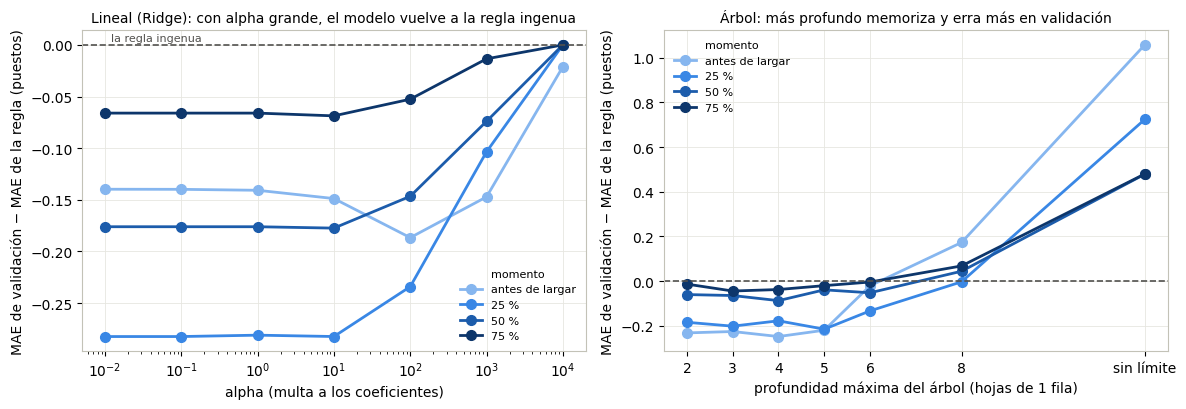

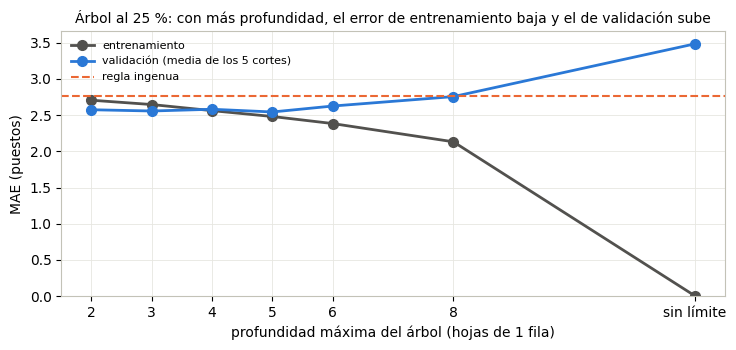

In [ ]:
TONOS = {0.0: "#86b6ef", 0.25: "#3987e5", 0.5: "#1c5cab", 0.75: "#0d366b"}     # un tono por momento, de claro a oscuro
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in MOMENTOS:
    regla = REF[m]["regla"].mean()
    lin = TABLAS_GRILLA[("regresión lineal", m)].assign(alpha=lambda t: t["alpha"].astype(float)).sort_values("alpha")
    axes[0].plot(lin["alpha"], lin["MAE validación"] - regla, color=TONOS[m], lw=2, marker="o", ms=7, label=NOMBRE[m])
    arbol = TABLAS_GRILLA[("árbol", m)]
    arbol = arbol[arbol["min_samples_leaf"] == "1"].copy()
    arbol["prof"] = arbol["max_depth"].apply(lambda d: 12 if str(d) in ("None", "nan") else int(float(d)))
    arbol = arbol.sort_values("prof")
    axes[1].plot(arbol["prof"], arbol["MAE validación"] - regla, color=TONOS[m], lw=2, marker="o", ms=7, label=NOMBRE[m])
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha (multa a los coeficientes)")
axes[0].set_title("Lineal (Ridge): con alpha grande, el modelo vuelve a la regla ingenua", fontsize=10)
axes[1].set_xticks([2, 3, 4, 5, 6, 8, 12])
axes[1].set_xticklabels(["2", "3", "4", "5", "6", "8", "sin límite"])
axes[1].set_xlabel("profundidad máxima del árbol (hojas de 1 fila)")
axes[1].set_title("Árbol: más profundo memoriza y erra más en validación", fontsize=10)
for ax in axes:
    ax.axhline(0, color="#52514e", ls="--", lw=1.2)
    ax.set_ylabel("MAE de validación − MAE de la regla (puestos)")
    ax.legend(title="momento", fontsize=8, title_fontsize=8, frameon=False)
axes[0].annotate("la regla ingenua", xy=(0.012, 0.004), fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()

# El árbol al 25 %: error de entrenamiento contra error de validación, según la profundidad
curva = TABLAS_GRILLA[("árbol", 0.25)]
curva = curva[curva["min_samples_leaf"] == "1"].copy()
curva["prof"] = curva["max_depth"].apply(lambda d: 12 if str(d) in ("None", "nan") else int(float(d)))
curva = curva.sort_values("prof")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(curva["prof"], curva["MAE entrenamiento"], color="#52514e", lw=2, marker="o", ms=7, label="entrenamiento")
ax.plot(curva["prof"], curva["MAE validación"], color="#2a78d6", lw=2, marker="o", ms=7,
        label="validación (media de los 5 cortes)")
ax.axhline(REF[0.25]["regla"].mean(), color="#eb6834", ls="--", lw=1.5, label="regla ingenua")
ax.set_xticks([2, 3, 4, 5, 6, 8, 12])
ax.set_xticklabels(["2", "3", "4", "5", "6", "8", "sin límite"])
ax.set_ylim(0, None)
ax.set_xlabel("profundidad máxima del árbol (hojas de 1 fila)")
ax.set_ylabel("MAE (puestos)")
ax.set_title("Árbol al 25 %: con más profundidad, el error de entrenamiento baja y el de validación sube", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

El ajuste ayuda sobre todo a los árboles: el árbol solo pasa de 4,369 a 3,050 antes de largar y de 1,879 a 1,354 al 75 %, y el bosque baja en todos los momentos (a 1,315 al 75 %). En la regresión lineal, la penalización de Ridge (`alpha`) sólo gana claro antes de largar (3,125 contra 3,172); con un `alpha` muy grande los coeficientes se apagan y el modelo vuelve a ser la regla ingenua. El boosting ajustado mejora antes de largar (2,911) y al 75 % (1,360).

El primer gráfico muestra el error de validación menos el de la regla: lo que queda por debajo de la línea punteada le gana. El segundo muestra, para el árbol al 25 %, el error de entrenamiento y el de validación según la profundidad: hasta 5 niveles van juntos, y después el de entrenamiento baja hasta 0,008 mientras el de validación sube hasta 3,481, por encima de la regla. Es la memorización vista en una curva.

### El modelo final de cada momento

Con cada familia en su mejor versión (la ajustada, sólo si le ganó claro a sus valores por defecto), repetimos la comparación desde la regresión lineal en cada momento.

In [ ]:
ELEGIDO, MODELO_FINAL, P_FINAL, MEJORES, filas = {}, {}, {}, {}, []
for m in MOMENTOS:
    p = {k: (medir(FINALES[m][k], m) if AJUSTADO[(m, k)] else COMPARACION[m][k]) for k in FINALES[m]}
    MEJORES[m] = p                                     # el MAE de cada corte, para el gráfico que sigue
    otros = sorted([k for k in p if k != "regresión lineal"], key=lambda k: p[k].mean())
    ELEGIDO[m] = elegir(p, ["regresión lineal"] + otros, titulo=f"\n{NOMBRE[m].upper()} (cada familia en su mejor versión)")
    MODELO_FINAL[m], P_FINAL[m] = FINALES[m][ELEGIDO[m]], p[ELEGIDO[m]]
    d_piso, d_regla = diferencia(P_FINAL[m], REF[m]["piso"]), diferencia(P_FINAL[m], REF[m]["regla"])
    filas.append({"momento": NOMBRE[m], "modelo final": ELEGIDO[m] + (" (ajustado)" if AJUSTADO[(m, ELEGIDO[m])] else ""),
                  "hiperparámetros": (AJUSTE.loc[(NOMBRE[m], ELEGIDO[m]), "mejores valores"]
                                      if AJUSTADO[(m, ELEGIDO[m])] else "por defecto"),
                  "formato": "orden de llegada" if ORDENAR[m] else "posición esperada",
                  "columnas": ", ".join(COLUMNAS[m][0] + COLUMNAS[m][1]),
                  "MAE validación": P_FINAL[m].mean(), "desvío": P_FINAL[m].std(),
                  "contra el piso: mejora": d_piso["mejora media (puestos)"],
                  "contra la regla: mejora": d_regla["mejora media (puestos)"],
                  "desvío de la mejora": d_regla["desvío de la mejora"], "cortes": d_regla["cortes en que mejora"],
                  "¿gana claro a la regla?": d_regla["¿gana claro?"]})
FINAL = pd.DataFrame(filas).set_index("momento")
FINAL.round(3)


ANTES DE LARGAR (cada familia en su mejor versión)


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,0.2136,0.0235,5 de 5,True
árbol,boosting,-0.1386,0.0652,0 de 5,False
bosque,boosting,-0.1519,0.0385,0 de 5,False



25 % (cada familia en su mejor versión)


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
boosting,regresión lineal,-0.0401,0.0891,1 de 5,False
árbol,regresión lineal,-0.0672,0.0466,0 de 5,False
bosque,regresión lineal,-0.0713,0.0634,0 de 5,False



50 % (cada familia en su mejor versión)


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
bosque,regresión lineal,-0.0174,0.0464,1 de 5,False
árbol,regresión lineal,-0.0549,0.0763,1 de 5,False
boosting,regresión lineal,-0.0780,0.0675,1 de 5,False



75 % (cada familia en su mejor versión)


,contra,mejora media (puestos),desvío de la mejora,cortes en que mejora,¿gana claro?
opción,,,,,
bosque,regresión lineal,0.0188,0.0382,2 de 5,False
árbol,regresión lineal,-0.0202,0.0338,2 de 5,False
boosting,regresión lineal,-0.0256,0.0316,2 de 5,False


,modelo final,hiperparámetros,formato,columnas,MAE validación,desvío,contra el piso: mejora,contra la regla: mejora,desvío de la mejora,cortes,¿gana claro a la regla?
momento,,,,,,,,,,,
antes de largar,boosting (ajustado),"learning_rate=0.03, max_iter=100, max_leaf_nodes=7",posición esperada,"posicion_al_corte, driver_standing_before, log_puntos",2.911,0.247,2.050,0.400,0.137,5 de 5,True
25 %,regresión lineal,por defecto,orden de llegada,"posicion_al_corte, vueltas_detras, tendencia_10, gap_qualy_pct, log_puntos_equipo",2.475,0.200,2.487,0.282,0.095,5 de 5,True
50 %,regresión lineal,por defecto,orden de llegada,"posicion_al_corte, vueltas_detras, neumatico_vs_carrera, tendencia_10",1.853,0.173,3.109,0.176,0.086,5 de 5,True
75 %,regresión lineal,por defecto,orden de llegada,"posicion_al_corte, neumatico_vs_carrera, tendencia_10",1.334,0.139,3.628,0.066,0.048,5 de 5,True


Antes de largar gana el boosting ajustado (2,911 contra 3,125 de la regresión lineal ajustada, en los 5 cortes). En los otros tres momentos se queda la regresión lineal sin penalización, porque ninguna familia le gana claro: al 75 %, el bosque erra 1,315 contra 1,334, pero mejora en sólo 2 de 5 cortes.

Contra la regla ingenua, los cuatro modelos finales ganan claro en validación, en los 5 cortes: por 0,400 puestos antes de largar, 0,282 al 25 %, 0,176 al 50 % y 0,066 al 75 %. Contra el piso ganan entre 2,05 y 3,63 puestos, pero casi todo eso lo hace la grilla o la posición en pista. Lo que el modelo agrega sobre la regla es mayor al principio (un 12 % menos de error antes de largar y un 10 % al 25 %) que al final (un 5 % al 75 %): al 75 % ya queda poco por predecir. Como es un problema de regresión, no hay clases desparejas que balancear.

### La comparación, dibujada

Cada opción se dibuja con un punto en la media de los 5 cortes y una barra de un desvío. En gris, una línea une los resultados de cada corte a través de todas las opciones.

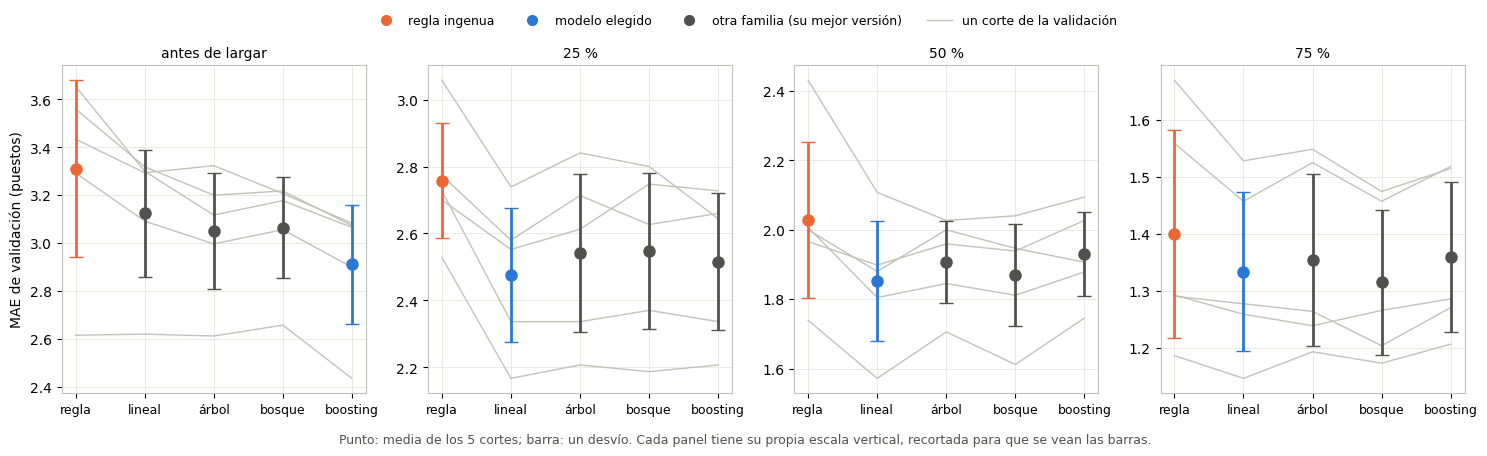

,desvío de la regla,desvío del modelo elegido,mejora sobre la regla,desvío de la mejora,cortes en que mejora
momento,,,,,
antes de largar,0.369,0.247,0.400,0.137,5 de 5
25 %,0.171,0.200,0.282,0.095,5 de 5
50 %,0.224,0.173,0.176,0.086,5 de 5
75 %,0.183,0.139,0.066,0.048,5 de 5


In [ ]:
# La comparación dibujada: el punto es la media de los 5 cortes y la barra, un desvío.
# Las líneas grises unen los resultados de un mismo corte con todas las opciones.
OPCIONES = {"regla": "regla", "regresión lineal": "lineal", "árbol": "árbol", "bosque": "bosque", "boosting": "boosting"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, m in zip(axes, MOMENTOS):
    p = {"regla": REF[m]["regla"], **MEJORES[m]}
    cortes = np.array([p[k] for k in OPCIONES])                    # una fila por opción, una columna por corte
    x = np.arange(len(OPCIONES))
    for i in range(cortes.shape[1]):
        ax.plot(x, cortes[:, i], color="#c3c2b7", lw=1, zorder=1)
    for j, k in enumerate(OPCIONES):
        color = "#eb6834" if k == "regla" else ("#2a78d6" if k == ELEGIDO[m] else "#52514e")
        ax.errorbar(x[j], cortes[j].mean(), yerr=cortes[j].std(), fmt="o", ms=8, color=color, ecolor=color,
                    elinewidth=2, capsize=5, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(OPCIONES.values(), fontsize=9)
    ax.set_title(NOMBRE[m], fontsize=10)
axes[0].set_ylabel("MAE de validación (puestos)")
marcas = [plt.Line2D([], [], color="#eb6834", marker="o", ls="", ms=7, label="regla ingenua"),
          plt.Line2D([], [], color="#2a78d6", marker="o", ls="", ms=7, label="modelo elegido"),
          plt.Line2D([], [], color="#52514e", marker="o", ls="", ms=7, label="otra familia (su mejor versión)"),
          plt.Line2D([], [], color="#c3c2b7", lw=1, label="un corte de la validación")]
fig.legend(handles=marcas, loc="upper center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.07))
fig.text(0.5, -0.03, "Punto: media de los 5 cortes; barra: un desvío. Cada panel tiene su propia escala vertical, "
         "recortada para que se vean las barras.", ha="center", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

# Los números detrás: el desvío de cada barra contra el desvío de la diferencia, corte por corte
filas = []
for m in MOMENTOS:
    regla, elegido = REF[m]["regla"], P_FINAL[m]
    filas.append({"momento": NOMBRE[m], "desvío de la regla": regla.std(), "desvío del modelo elegido": elegido.std(),
                  "mejora sobre la regla": (regla - elegido).mean(), "desvío de la mejora": (regla - elegido).std(),
                  "cortes en que mejora": f"{int(((regla - elegido) > 0).sum())} de {len(regla)}"})
BARRAS = pd.DataFrame(filas).set_index("momento")
BARRAS.round(3)

Las barras se superponen en los cuatro momentos. Al 75 %, la ventaja del modelo sobre la regla (0,066 puestos) es más chica que el desvío de cualquiera de las dos barras (0,139 la del modelo y 0,183 la de la regla): leídas sueltas, no habría diferencia.

Las líneas grises muestran por qué no conviene leerlas así. Cada corte valida carreras distintas, y un corte difícil (por ejemplo, uno con muchos abandonos) es difícil para todas las opciones a la vez: las líneas suben y bajan juntas. El desvío de cada barra mide sobre todo cuánto cambia la dificultad de un corte a otro, no cuánto se distinguen los modelos. Por eso comparamos la diferencia dentro de cada corte: al 75 %, el modelo le gana a la regla en los 5 cortes, y esa diferencia tiene un desvío de 0,048, menor que la ventaja. Antes de largar, el boosting le gana a la regresión lineal por 0,214, con un desvío de 0,02, mientras que la barra del boosting tiene un desvío de 0,247.

## 6. El test: las 14 carreras de 2026, una sola vez por momento

Todo lo anterior se eligió con validación cruzada sobre 2022–2025. Recién ahora cada modelo final se entrena con las 92 carreras de 2022–2025 y se mide en 2026. Al lado van el piso y la regla, sólo como referencia: no cambian ninguna decisión.

,MAE del modelo,MAE de la regla,MAE del piso,MAE del modelo en validación,MAE de la regla en validación,carreras mejor que la regla,igual,peor
momento,,,,,,,,
antes de largar,3.040,3.130,5.465,2.911,3.311,7,0,7
25 %,2.332,2.319,5.465,2.475,2.757,5,2,7
50 %,1.654,1.681,5.465,1.853,2.029,7,4,3
75 %,1.249,1.143,5.465,1.334,1.400,2,2,10


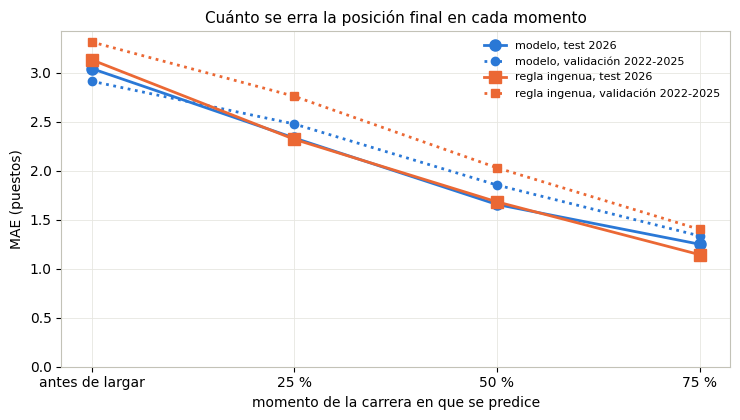

In [ ]:
# En cada momento, el modelo final se entrena con 2022-2025 completo y se mide UNA vez en 2026.
# El piso y la regla van al lado sólo para leer el número: no cambian ninguna decisión.
PRED_TEST, MODELOS_ENTRENADOS, filas, por_carrera = {}, {}, [], {}
for m in MOMENTOS:
    d = DATOS[m]
    MODELOS_ENTRENADOS[m] = clone(MODELO_FINAL[m]).fit(d["X"], d["y"])
    PRED_TEST[m] = MODELOS_ENTRENADOS[m].predict(d["X_test"])
    real = d["y_test"].to_numpy()
    regla = d["X_test"]["posicion_al_corte"].to_numpy()
    piso = DummyRegressor(strategy="median").fit(d["X"], d["y"]).predict(d["X_test"])
    pc = pd.DataFrame({"carrera": d["X_test"]["carrera"].to_numpy(), "modelo": np.abs(PRED_TEST[m] - real),
                       "regla": np.abs(regla - real)}).groupby("carrera").mean()
    por_carrera[NOMBRE[m]] = pc
    filas.append({"momento": NOMBRE[m], "MAE del modelo": mean_absolute_error(real, PRED_TEST[m]),
                  "MAE de la regla": mean_absolute_error(real, regla), "MAE del piso": mean_absolute_error(real, piso),
                  "MAE del modelo en validación": P_FINAL[m].mean(), "MAE de la regla en validación": REF[m]["regla"].mean(),
                  "carreras mejor que la regla": int((pc["modelo"] < pc["regla"]).sum()),
                  "igual": int((pc["modelo"] == pc["regla"]).sum()), "peor": int((pc["modelo"] > pc["regla"]).sum())})
TEST = pd.DataFrame(filas).set_index("momento")
display(TEST.round(3))

x = [0, 25, 50, 75]
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(x, TEST["MAE del modelo"], color="#2a78d6", lw=2, marker="o", ms=8, label="modelo, test 2026")
ax.plot(x, TEST["MAE del modelo en validación"], color="#2a78d6", lw=2, ls=":", marker="o", ms=6,
        label="modelo, validación 2022-2025")
ax.plot(x, TEST["MAE de la regla"], color="#eb6834", lw=2, marker="s", ms=8, label="regla ingenua, test 2026")
ax.plot(x, TEST["MAE de la regla en validación"], color="#eb6834", lw=2, ls=":", marker="s", ms=6,
        label="regla ingenua, validación 2022-2025")
ax.set_xticks(x)
ax.set_xticklabels(["antes de largar", "25 %", "50 %", "75 %"])
ax.set_xlabel("momento de la carrera en que se predice")
ax.set_ylabel("MAE (puestos)")
ax.set_ylim(0, None)
ax.set_title("Cuánto se erra la posición final en cada momento", fontsize=11)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

En 2026 el modelo erra 3,040 puestos antes de largar, 2,332 al 25 %, 1,654 al 50 % y 1,249 al 75 %; el piso erra 5,465. Contra la regla, el resultado es mixto: el modelo gana antes de largar (3,040 contra 3,130) y al 50 % (1,654 contra 1,681), prácticamente empata al 25 % (2,332 contra 2,319) y pierde al 75 % (1,249 contra 1,143). Carrera por carrera, es mejor que la regla en 7 de las 14 antes de largar, en 5 al 25 %, en 7 al 50 % y en 2 al 75 %.

Las ventajas de 2022–2025 se achicaron en 2026, y al 75 % se dieron vuelta. No cambiamos nada después de ver estos números, porque si lo hiciéramos el test dejaría de ser un test. Las secciones que siguen buscan entender por qué pasó.

### La tabla completa de cada carrera

El MAE mide cuánto erra el modelo con cada piloto, uno por uno. Pero lo que predecimos, en el fondo, es una tabla de posiciones: conviene medir también si la tabla que arma el modelo se parece a la tabla final, con todos los pilotos a la vez. Para cada carrera ordenamos a los pilotos según la predicción (si dos empatan, adelante el que va adelante) y la comparamos con el orden de llegada con tres números:

- **Correlación de Spearman** entre el puesto predicho y el puesto final: 1 si las dos tablas son idénticas, 0 si no tienen nada que ver. Compara órdenes, no distancias.
- **Aciertos del podio:** de los 3 primeros de la tabla predicha, qué parte terminó en el podio.
- **Aciertos del top 10:** de los 10 primeros predichos, qué parte terminó en la zona de puntos.

Se calculan carrera por carrera y se promedian. En la validación usamos los mismos 5 cortes y los mismos modelos finales; en el test, las 14 carreras de 2026. La regla ingenua también arma una tabla (la grilla, o el orden en ese momento), así que se compara igual. Ninguna decisión cambia por estos números: el modelo ya estaba elegido con el MAE.

In [ ]:
# La tabla completa de cada carrera: el orden que arma el modelo contra el orden final.
# Spearman compara los dos órdenes (1 = idénticos, 0 = nada que ver). Podio y top 10 cuentan cuántos
# de los que el modelo pone adelante terminaron efectivamente ahí, sin importar en qué orden.
from scipy.stats import spearmanr


def tabla_por_carrera(carrera, pos, pred, real):
    """Una fila por carrera: Spearman y aciertos del podio y del top 10 de la tabla predicha."""
    d = pd.DataFrame({"carrera": carrera, "pos": pos, "pred": pred, "real": real})
    filas = []
    for c, t in d.groupby("carrera"):
        # la tabla predicha: ordenada por la predicción y, si empatan, por dónde va cada uno
        t = t.sort_values(["pred", "pos"]).reset_index(drop=True)
        puesto_predicho = np.arange(1, len(t) + 1)
        filas.append({"carrera": c,
                      "spearman": spearmanr(puesto_predicho, t["real"]).statistic,
                      "podio": (t["real"].head(3) <= 3).mean(),
                      "top 10": (t["real"].head(10) <= 10).mean()})
    return pd.DataFrame(filas).set_index("carrera")


METRICAS = ["spearman", "podio", "top 10"]
filas_val, filas_test = [], []
for m in MOMENTOS:
    d = DATOS[m]
    # validación: los mismos 5 cortes; cada corte da el promedio de sus carreras validadas
    por_corte = {"modelo": [], "regla": []}
    for e, w in d["cortes"]:
        Xw = d["X"].iloc[w]
        pred = clone(MODELO_FINAL[m]).fit(d["X"].iloc[e], d["y"].iloc[e]).predict(Xw)
        for quien, p in [("modelo", pred), ("regla", Xw["posicion_al_corte"].to_numpy())]:
            por_corte[quien].append(tabla_por_carrera(Xw["carrera"].to_numpy(), Xw["posicion_al_corte"].to_numpy(),
                                                      p, d["y"].iloc[w].to_numpy()).mean())
    fila = {"momento": NOMBRE[m]}
    for met in METRICAS:
        for quien in ["modelo", "regla"]:
            v = pd.DataFrame(por_corte[quien])[met]
            fila[f"{met}, {quien}"] = f"{v.mean():.3f} ± {v.std():.3f}"
        dif = pd.DataFrame(por_corte["modelo"])[met] - pd.DataFrame(por_corte["regla"])[met]
        fila[f"{met}: cortes en que gana el modelo"] = int((dif > 0).sum())
    filas_val.append(fila)
    # test: el modelo entrenado con 2022-2025, sobre las 14 carreras de 2026
    Xt = d["X_test"]
    tm = tabla_por_carrera(Xt["carrera"].to_numpy(), Xt["posicion_al_corte"].to_numpy(), PRED_TEST[m], d["y_test"].to_numpy())
    tr = tabla_por_carrera(Xt["carrera"].to_numpy(), Xt["posicion_al_corte"].to_numpy(),
                           Xt["posicion_al_corte"].to_numpy(), d["y_test"].to_numpy())
    fila = {"momento": NOMBRE[m]}
    for met in METRICAS:
        fila[f"{met}, modelo"], fila[f"{met}, regla"] = tm[met].mean(), tr[met].mean()
    fila["carreras con mejor Spearman / igual / peor"] = (f"{int((tm['spearman'] > tr['spearman']).sum())} / "
                                                         f"{int((tm['spearman'] == tr['spearman']).sum())} / "
                                                         f"{int((tm['spearman'] < tr['spearman']).sum())}")
    filas_test.append(fila)

TABLA_VAL = pd.DataFrame(filas_val).set_index("momento")
TABLA_TEST = pd.DataFrame(filas_test).set_index("momento")
print("Validación 2022-2025 (media ± desvío de los 5 cortes)")
display(TABLA_VAL)
print("Test 2026 (promedio de las 14 carreras)")
display(TABLA_TEST.round(3))


Validación 2022-2025 (media ± desvío de los 5 cortes)


,"spearman, modelo","spearman, regla",spearman: cortes en que gana el modelo,"podio, modelo","podio, regla",podio: cortes en que gana el modelo,"top 10, modelo","top 10, regla",top 10: cortes en que gana el modelo
momento,,,,,,,,,
antes de largar,0.688 ± 0.056,0.653 ± 0.075,5,0.698 ± 0.073,0.693 ± 0.067,1,0.797 ± 0.034,0.784 ± 0.048,3
25 %,0.783 ± 0.032,0.747 ± 0.026,5,0.751 ± 0.058,0.738 ± 0.102,3,0.835 ± 0.024,0.808 ± 0.023,4
50 %,0.859 ± 0.014,0.844 ± 0.023,5,0.831 ± 0.020,0.818 ± 0.043,3,0.869 ± 0.021,0.852 ± 0.017,4
75 %,0.906 ± 0.020,0.899 ± 0.024,5,0.880 ± 0.056,0.876 ± 0.037,2,0.909 ± 0.020,0.897 ± 0.025,4


Test 2026 (promedio de las 14 carreras)


,"spearman, modelo","spearman, regla","podio, modelo","podio, regla","top 10, modelo","top 10, regla",carreras con mejor Spearman / igual / peor
momento,,,,,,,
antes de largar,0.690,0.682,0.619,0.619,0.771,0.764,5 / 0 / 9
25 %,0.823,0.821,0.762,0.738,0.864,0.850,4 / 1 / 9
50 %,0.880,0.882,0.738,0.762,0.879,0.864,7 / 3 / 4
75 %,0.914,0.918,0.786,0.810,0.914,0.914,2 / 1 / 11


Mirada como tabla, la historia es la misma que con el MAE. En la validación, la tabla del modelo se parece más a la final que la de la regla en los cuatro momentos y en los 5 cortes: Spearman de 0,688 contra 0,653 antes de largar, 0,783 contra 0,747 al 25 %, 0,859 contra 0,844 al 50 % y 0,906 contra 0,899 al 75 %. La ventaja se achica a medida que avanza la carrera, y al 75 % es menor que el desvío entre cortes.

El podio casi no cambia: antes de largar, 7 de cada 10 pilotos del podio predicho terminan en el podio, igual que con la grilla (0,698 contra 0,693), y al 75 % son casi 9 de cada 10 con los dos. Los que van adelante suelen seguir adelante, y ahí el modelo tiene poco para agregar. Donde ordena mejor es en la zona de puntos: acierta 8 de cada 10 del top 10 antes de largar (0,797 contra 0,784) y gana en 4 de los 5 cortes del 25 % en adelante.

En 2026 las dos tablas quedan prácticamente iguales: Spearman de 0,690 contra 0,682 antes de largar, 0,823 contra 0,821 al 25 %, 0,880 contra 0,882 al 50 % y 0,914 contra 0,918 al 75 %. Carrera por carrera, la tabla del modelo se parece más a la final en 5, 4, 7 y 2 de las 14. Como con el MAE, la ventaja medida en 2022–2025 no se sostuvo entera en el test.

## 7. Dónde se equivoca

Leemos los modelos finales en el test: lo real contra lo predicho, el error según lo que le pasó a cada piloto y por tramo de llegada, los errores más grandes y qué pasa cuando el modelo se aparta de la regla.

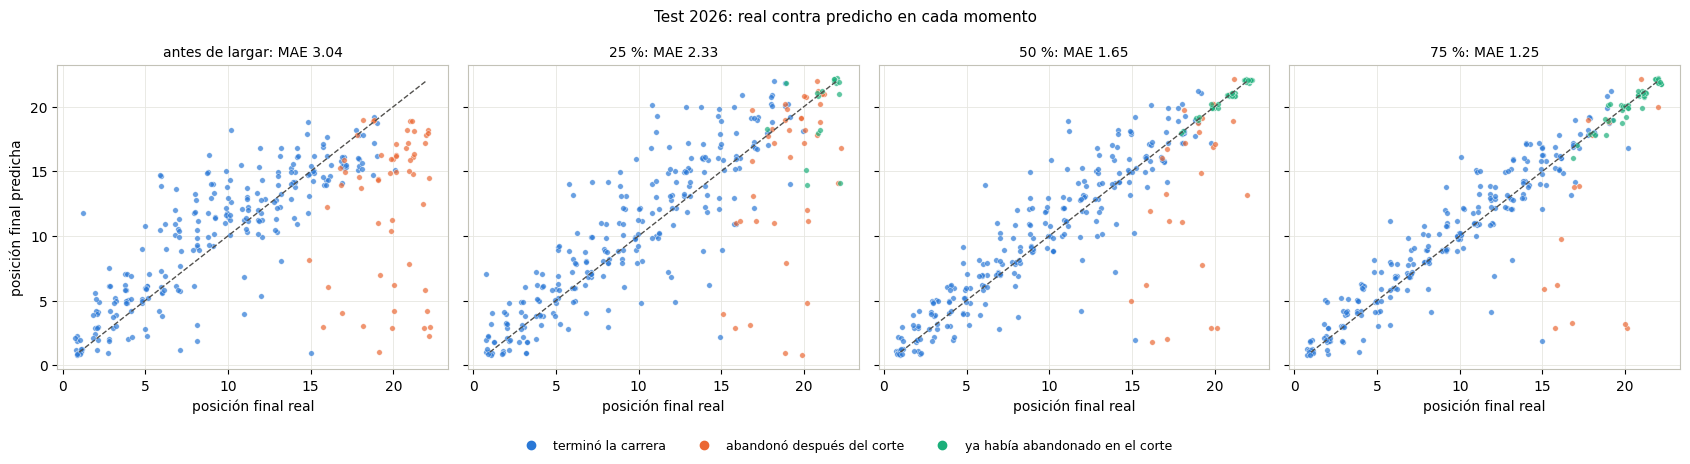

MAE según lo que le pasó a cada piloto


filas                               modelo                             regla                  
momento                         antes de largar   25 %   50 %   75 % antes de largar  25 %  50 %  75 % antes de largar  25 %  50 %  75 %
situación                                                                                                                               
abandonó después del corte                 57.0   39.0   27.0   15.0            7.13  4.74  5.26  6.40            6.09  4.67  5.30  5.93
terminó la carrera                        244.0  244.0  244.0  244.0            2.08  2.00  1.46  1.12            2.44  2.11  1.49  1.05
ya había abandonado en el corte             NaN   18.0   30.0   42.0             NaN  1.61  0.00  0.17             NaN  0.00  0.00  0.00

MAE por tramo de la posición final


filas                         modelo                             regla                  
momento          antes de largar 25 % 50 % 75 % antes de largar  25 %  50 %  75 % antes de largar  25 %  50 %  75 %
tramo de llegada                                                                                                   
P1-P5                         70   70   70   70            1.51  1.26  0.99  0.80            1.60  1.49  1.04  0.79
P6-P10                        70   70   70   70            3.09  2.00  1.46  1.10            3.24  2.06  1.57  1.04
P11-P15                       70   70   70   70            1.94  2.91  2.21  1.73            2.74  3.10  2.19  1.56
P16-P22                       91   91   91   91            5.03  2.97  1.89  1.34            4.52  2.56  1.87  1.18

In [ ]:
partes = []
for m in MOMENTOS:
    t = DATOS[m]["test"]
    l = t[["carrera", "driver_code", "constructor_name", "posicion_al_corte", "finish_position", "status"]].copy()
    l["momento"] = NOMBRE[m]
    l["predicha"] = PRED_TEST[m]
    l["error"] = l["predicha"] - l["finish_position"]
    l["error regla"] = l["posicion_al_corte"] - l["finish_position"]
    derivadas = EstadoEnCarrera().fit(DATOS[m]["X_test"]).transform(DATOS[m]["X_test"])
    terminó = t["status"].str.contains("Finished|Lap", regex=True)
    l["situación"] = np.select([derivadas["vueltas_detras"] > 2, terminó],
                               ["ya había abandonado en el corte", "terminó la carrera"], "abandonó después del corte")
    partes.append(l)
LECTURA = pd.concat(partes, ignore_index=True)
LECTURA["momento"] = pd.Categorical(LECTURA["momento"], [NOMBRE[m] for m in MOMENTOS], ordered=True)
LECTURA["tramo de llegada"] = pd.cut(LECTURA["finish_position"], [0, 5, 10, 15, 22],
                                     labels=["P1-P5", "P6-P10", "P11-P15", "P16-P22"])

COLORES = {"terminó la carrera": "#2a78d6", "abandonó después del corte": "#eb6834",
           "ya había abandonado en el corte": "#1baf7a"}
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharex=True, sharey=True)
for ax, m in zip(axes, MOMENTOS):
    parte = LECTURA[LECTURA["momento"] == NOMBRE[m]]
    for situacion, color in COLORES.items():
        p = parte[parte["situación"] == situacion]
        if len(p):
            ax.scatter(p["finish_position"] + rng.uniform(-0.25, 0.25, len(p)),
                       p["predicha"] + rng.uniform(-0.25, 0.25, len(p)), s=16, alpha=0.7, color=color,
                       edgecolor="white", linewidth=0.4, label=situacion)
    ax.plot([1, 22], [1, 22], color="#52514e", lw=1, ls="--")
    ax.set_title(f"{NOMBRE[m]}: MAE {TEST.loc[NOMBRE[m], 'MAE del modelo']:.2f}", fontsize=10)
    ax.set_xlabel("posición final real")
axes[0].set_ylabel("posición final predicha")
marcas = [plt.Line2D([], [], ls="", marker="o", ms=6, color=c, label=k) for k, c in COLORES.items()]
fig.legend(handles=marcas, loc="lower center", ncol=3, fontsize=9, frameon=False)
plt.suptitle("Test 2026: real contra predicho en cada momento", fontsize=11)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

def mae_por(grupo):
    t = LECTURA.groupby(["momento", grupo], observed=True).agg(
        filas=("error", "size"), modelo=("error", lambda e: e.abs().mean()),
        regla=("error regla", lambda e: e.abs().mean()))
    return t.unstack("momento").reindex(columns=[NOMBRE[m] for m in MOMENTOS], level=1)

POR_SITUACION, POR_TRAMO = mae_por("situación"), mae_por("tramo de llegada")
print("MAE según lo que le pasó a cada piloto")
display(POR_SITUACION.round(2))
print("MAE por tramo de la posición final")
POR_TRAMO.round(2)

Los gráficos muestran cómo se cierra la nube a medida que avanza la carrera. Los errores grandes son los abandonos después del corte (los puntos naranjas): son 57 pilotos antes de largar y 15 al 75 %, y erran entre 4,7 y 7,1 puestos, como la regla, porque nadie podía saber que ese auto iba a romperse o chocar. Donde el modelo le gana a la regla es en los que terminan la carrera, hasta el 50 %: antes de largar erra 2,08 contra 2,44, al 25 % 2,00 contra 2,11 y al 50 % 1,46 contra 1,49. Al 75 % pierde también ahí (1,12 contra 1,05).

Hay una confusión concreta con los autos que ya habían abandonado en el corte. Un auto parado no puede ganar puestos, pero los puestos que perdió al abandonar parecen una caída que se va a recuperar, y su neumático parece nuevo porque dejó de sumar vueltas. Al 25 % el modelo movió a 7 de los 18 abandonados (1,61 puestos de error, contra 0 de la regla): Hamilton, en la fecha 14, había perdido 19 puestos en las últimas 10 vueltas, y el modelo lo subió del 22 al 14. Al 75 % movió a 7 de 42.

Por tramos, antes de largar el modelo erra menos que la regla en la mitad del pelotón (P11–P15: 1,94 contra 2,74) y más en el fondo (P16–P22: 5,03 contra 4,52): espera que los que largan atrás remonten, y muchas veces no pasa.

In [ ]:
# Los tres errores más grandes de cada momento
display(LECTURA.assign(abs_error=LECTURA["error"].abs()).sort_values("abs_error", ascending=False)
        .groupby("momento", observed=True).head(3).sort_values(["momento", "abs_error"], ascending=[True, False])
        [["momento", "carrera", "driver_code", "constructor_name", "posicion_al_corte", "predicha",
          "finish_position", "status"]].set_index("momento"))

# ¿Cuándo se aparta el modelo de la regla, y le sirve?
filas = []
for m in MOMENTOS:
    l = LECTURA[LECTURA["momento"] == NOMBRE[m]]
    mueve = l["predicha"].round() != l["posicion_al_corte"]          # sin ordenar, la predicción no es entera
    acierta = (np.sign(l["predicha"] - l["posicion_al_corte"]) == np.sign(l["finish_position"] - l["posicion_al_corte"]))
    ab = l[l["situación"] == "ya había abandonado en el corte"]
    filas.append({"momento": NOMBRE[m], "pilotos movidos": int(mueve.sum()), "de": len(l),
                  "MAE del modelo en los movidos": l.loc[mueve, "error"].abs().mean(),
                  "MAE de la regla en los movidos": l.loc[mueve, "error regla"].abs().mean(),
                  "acierta la dirección": acierta[mueve].mean(),
                  "abandonados que movió": int((ab["predicha"].round() != ab["posicion_al_corte"]).sum()),
                  "abandonados": len(ab)})
MOVIDOS = pd.DataFrame(filas).set_index("momento")
display(MOVIDOS.round(3))

# ¿Cuánto se mueven las posiciones después de cada momento, por temporada? (sólo para leer, no decide nada)
TEMPORADAS = pd.concat({NOMBRE[m]: pd.concat([DATOS[m]["train"], DATOS[m]["test"]]).assign(
    igual=lambda t: t["finish_position"] == t["posicion_al_corte"]).groupby("season")["igual"].mean()
    for m in MOMENTOS}, axis=1)
print("Proporción de pilotos que terminan exactamente en el puesto que tenían en el corte")
lluvia = pd.concat([DATOS[0.75]["train"], DATOS[0.75]["test"]]).groupby("season")["uso_lluvia"].mean()
TEMPORADAS.assign(**{"usaron lluvia hasta el 75 %": lluvia}).round(3).T

,carrera,driver_code,constructor_name,posicion_al_corte,predicha,finish_position,status
momento,,,,,,,
antes de largar,2026-06,VER,Red Bull,2,2.050335,22,Retired
antes de largar,2026-10,RUS,Mercedes,3,2.983613,22,Retired
antes de largar,2026-13,LEC,Ferrari,3,3.006678,22,Retired
25 %,2026-11,PIA,McLaren,3,1.000000,20,Retired
25 %,2026-05,RUS,Mercedes,1,1.000000,19,Retired
25 %,2026-09,VER,Red Bull,5,5.000000,20,Retired
50 %,2026-11,PIA,McLaren,5,3.000000,20,Retired
50 %,2026-09,VER,Red Bull,4,3.000000,20,Retired
50 %,2026-06,LEC,Ferrari,3,2.000000,17,Retired


,pilotos movidos,de,MAE del modelo en los movidos,MAE de la regla en los movidos,acierta la dirección,abandonados que movió,abandonados
momento,,,,,,,
antes de largar,177,301,3.024,3.175,0.554,0,0
25 %,150,301,2.573,2.547,0.527,7,18
50 %,106,301,2.472,2.547,0.557,0,30
75 %,59,301,1.915,1.373,0.237,7,42


Proporción de pilotos que terminan exactamente en el puesto que tenían en el corte


season,2022,2023,2024,2025,2026
antes de largar,0.119,0.142,0.153,0.179,0.159
25 %,0.231,0.220,0.208,0.250,0.249
50 %,0.295,0.319,0.298,0.284,0.346
75 %,0.434,0.413,0.431,0.359,0.538
usaron lluvia hasta el 75 %,0.183,0.080,0.120,0.122,0.023


Los errores más grandes de cada momento son abandonos, como Verstappen en la fecha 6 de 2026, que largaba segundo y terminó vigésimo segundo. Cuando el modelo se aparta de la regla, antes de largar y al 50 % le sirve (en esos pilotos erra 3,02 contra 3,18, y 2,47 contra 2,55), al 25 % casi empata y al 75 % no (1,92 contra 1,37, y acierta hacia dónde se mueve el piloto sólo en el 24 % de los casos).

La última tabla ayuda a entender por qué el final de 2026 fue distinto. En 2026, más pilotos que nunca terminaron exactamente donde estaban al 50 % (el 35 %, contra entre el 28 % y el 32 % antes) y al 75 % (el 54 %, contra entre el 36 % y el 43 %), y casi no hubo lluvia (el 2 % de los pilotos usó neumáticos de lluvia hasta el 75 %, contra entre el 8 % y el 18 %). El modelo aprendió de 2022–2025 que un neumático más viejo que el del resto y los puestos ganados en las últimas vueltas anuncian puestos perdidos al final, porque todavía falta una parada. En la primera temporada del reglamento nuevo, esos movimientos tardíos pasaron menos. ¿Pudo ser por la falta de lluvia? La sección siguiente lo mide.

### ¿La validación imita al test?

La lluvia mueve las posiciones, y 2026 fue casi seco: si la ventaja del modelo viniera de las carreras con lluvia, un 2026 seco explicaría por qué se achicó. Se puede medir sin tocar el test, con las predicciones de validación de 2022–2025: separamos las carreras con lluvia (las que algún auto corrió con neumáticos intermedios o de lluvia) de las secas, y recalculamos la validación con la mezcla de carreras de 2026. La ventaja en el test va al lado sólo para comparar.

In [ ]:
# ¿La validación imita al test? La ventaja del modelo sobre la regla en carreras con y sin lluvia,
# con las predicciones de validación de 2022-2025, y lo que daría la validación con la mezcla de carreras de 2026.
# "Con lluvia" = algún auto usó intermedios o de lluvia en la carrera. Sólo describe: no es una columna del modelo.
vueltas_c = vueltas.assign(carrera=vueltas["season"].astype(str) + "-" + vueltas["round"].astype(str).str.zfill(2))
CON_LLUVIA = vueltas_c.groupby("carrera")["compound"].apply(lambda c: c.isin(["INTERMEDIATE", "WET"]).any())

filas = []
for m in MOMENTOS:
    Xm, ym = DATOS[m]["X"], DATOS[m]["y"]
    pred = pd.Series(np.nan, index=Xm.index)
    for e, w in DATOS[m]["cortes"]:                       # el modelo final, entrenado de nuevo en cada corte
        pred.iloc[w] = clone(MODELO_FINAL[m]).fit(Xm.iloc[e], ym.iloc[e]).predict(Xm.iloc[w])
    val = Xm.loc[pred.notna(), ["carrera", "posicion_al_corte"]].assign(y=ym, pred=pred)
    val["lluvia"] = val["carrera"].map(CON_LLUVIA).eq(True)
    val["ventaja"] = (val["y"] - val["posicion_al_corte"]).abs() - (val["y"] - val["pred"]).abs()
    carreras_val = val.groupby("carrera")["lluvia"].first()
    carreras_2026 = pd.Series(DATOS[m]["X_test"]["carrera"].unique()).map(CON_LLUVIA).eq(True)
    con, seca = val.loc[val["lluvia"], "ventaja"].mean(), val.loc[~val["lluvia"], "ventaja"].mean()
    filas.append({"momento": NOMBRE[m], "carreras validadas": len(carreras_val),
                  "con lluvia (validación)": int(carreras_val.sum()),
                  "carreras de 2026": len(carreras_2026), "con lluvia (2026)": int(carreras_2026.sum()),
                  "ventaja en las secas": seca, "ventaja con lluvia": con,
                  "ventaja en la validación": val["ventaja"].mean(),
                  "ventaja con la mezcla de 2026": carreras_2026.mean() * con + (1 - carreras_2026.mean()) * seca,
                  "ventaja en el test 2026": TEST.loc[NOMBRE[m], "MAE de la regla"] - TEST.loc[NOMBRE[m], "MAE del modelo"]})
LLUVIA = pd.DataFrame(filas).set_index("momento")
print("Ventaja = MAE de la regla − MAE del modelo (positiva: el modelo erra menos que la regla)")
LLUVIA.round(3)

Ventaja = MAE de la regla − MAE del modelo (positiva: el modelo erra menos que la regla)


,carreras validadas,con lluvia (validación),carreras de 2026,con lluvia (2026),ventaja en las secas,ventaja con lluvia,ventaja en la validación,ventaja con la mezcla de 2026,ventaja en el test 2026
momento,,,,,,,,,
antes de largar,75,9,14,1,0.413,0.299,0.400,0.405,0.089
25 %,75,9,14,1,0.328,-0.057,0.282,0.300,-0.013
50 %,75,9,14,1,0.203,-0.023,0.176,0.187,0.027
75 %,75,9,14,1,0.062,0.091,0.066,0.065,-0.106


La lluvia no lo explica. En la validación, la ventaja del modelo sale de las carreras secas: antes de largar le gana a la regla por 0,413 puestos en las secas y por 0,299 en las 9 carreras con lluvia, y al 25 y al 50 % gana en las secas (por 0,328 y 0,203) y pierde en las de lluvia (por 0,057 y 0,023). Sólo al 75 % la ventaja es algo mayor con lluvia (0,091 contra 0,062). Con la mezcla de 2026, 1 carrera con lluvia de 14 contra 9 de 75 en la validación, la ventaja esperada casi no cambia (0,405, 0,300, 0,187 y 0,065) y queda lejos de lo que dio el test. Son pocas carreras con lluvia, pero alcanzan para descartar que un 2026 seco explique la caída. Quedan el reglamento nuevo o una racha, y con 14 carreras no alcanza para distinguirlos.

## 8. En qué se apoya

Los modelos del 25, 50 y 75 % son lineales, así que se pueden leer sus coeficientes con su signo. El de antes de largar es un boosting, que no tiene coeficientes. Para los cuatro calculamos la importancia por permutación sobre el test: cuánto sube el error si se mezcla al azar cada columna de entrada.

In [ ]:
# En qué se apoya cada modelo final: coeficientes (si es lineal) e importancia por permutación en el test
ORIGEN = {"posicion_al_corte": ["posicion_al_corte"], "vueltas_detras": ["ultima_vuelta"],
          "neumatico_vs_carrera": ["vueltas_neumatico", "ultima_vuelta"],
          "paradas_vs_carrera": ["paradas_al_corte", "ultima_vuelta"],
          "debe_parar": ["compuestos_secos", "uso_lluvia", "ultima_vuelta"], "tendencia_10": ["pos_hace_10"],
          "ritmo_vs_carrera": ["ritmo_5"], "grilla": ["grid_position"], "grilla_x_posicion": ["grid_position"],
          "driver_standing_before": ["driver_standing_before"], "log_puntos": ["driver_points_before"],
          "gap_qualy_pct": ["quali_best_s"], "log_puntos_equipo": ["driver_points_before", "constructor_name"],
          "constructor_name": ["constructor_name"], "compound_at_cutoff": ["compound_at_cutoff"]}

coef = {}
for m in MOMENTOS:
    interno = MODELOS_ENTRENADOS[m].pipeline_.named_steps["modelo"]
    if not hasattr(interno, "coef_"):
        continue
    preparar = MODELOS_ENTRENADOS[m].pipeline_.named_steps["preparar"]
    nombres = [n.split("__", 1)[1] for n in preparar.get_feature_names_out()]
    escala = pd.Series(1.0, index=nombres)
    escala[COLUMNAS[m][0]] = preparar.named_transformers_["numericas"].named_steps["escalar"].scale_
    coef[(NOMBRE[m], "por desvío")] = pd.Series(interno.coef_, index=nombres)
    coef[(NOMBRE[m], "por unidad")] = pd.Series(interno.coef_, index=nombres) / escala
COEF = pd.DataFrame(coef)
print("Coeficientes de los modelos lineales, en puestos de CAMBIO (positivo = pierde puestos).")
print("'Por unidad' es por puesto, por vuelta o por punto de log, según la columna; las de equipo son 0/1.")
display(COEF.round(3))

def importancia_por_permutacion(modelo, X, y, columnas, repeticiones=30, semilla=SEMILLA):
    """Cuánto sube el MAE si se mezcla al azar cada columna de entrada (rompe su relación con la llegada)."""
    rng = np.random.default_rng(semilla)
    base = mean_absolute_error(y, modelo.predict(X))
    salida = {}
    for col in columnas:
        subas = []
        for _ in range(repeticiones):
            Xp = X.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            subas.append(mean_absolute_error(y, modelo.predict(Xp)) - base)
        salida[col] = np.mean(subas)
    return pd.Series(salida)

IMPORTANCIA = pd.DataFrame({NOMBRE[m]: importancia_por_permutacion(
    MODELOS_ENTRENADOS[m], DATOS[m]["X_test"], DATOS[m]["y_test"],
    sorted({c for col in COLUMNAS[m][0] + COLUMNAS[m][1] for c in ORIGEN[col]})) for m in MOMENTOS})
CORR_GRILLA_STANDING = (DATOS[0.0]["train"][["grid_position", "driver_standing_before"]]
                        .corr(method="spearman").iloc[0, 1])
print(f"Grilla y standing antes de largar (2022-2025): correlación de Spearman {CORR_GRILLA_STANDING:.2f}")
print("Importancia por permutación en el test: cuánto sube el MAE al mezclar cada columna de entrada")
IMPORTANCIA.round(3)

Coeficientes de los modelos lineales, en puestos de CAMBIO (positivo = pierde puestos).
'Por unidad' es por puesto, por vuelta o por punto de log, según la columna; las de equipo son 0/1.


25 %                  50 %                  75 %           
                     por desvío por unidad por desvío por unidad por desvío por unidad
gap_qualy_pct             0.211      0.090        NaN        NaN        NaN        NaN
log_puntos_equipo        -0.697     -0.373        NaN        NaN        NaN        NaN
neumatico_vs_carrera        NaN        NaN      0.767      0.090      0.470      0.051
posicion_al_corte        -1.775     -0.310     -0.805     -0.140     -0.395     -0.069
tendencia_10              1.019      0.303      0.421      0.129      0.324      0.127
vueltas_detras            0.568      0.235      0.537      0.097        NaN        NaN

Grilla y standing antes de largar (2022-2025): correlación de Spearman 0.64
Importancia por permutación en el test: cuánto sube el MAE al mezclar cada columna de entrada


,antes de largar,25 %,50 %,75 %
constructor_name,NaN,0.022,NaN,NaN
driver_points_before,0.101,0.084,NaN,NaN
driver_standing_before,0.355,NaN,NaN,NaN
pos_hace_10,NaN,1.111,0.243,0.267
posicion_al_corte,2.729,2.171,4.880,5.629
quali_best_s,NaN,0.365,NaN,NaN
ultima_vuelta,NaN,0.237,0.227,0.000
vueltas_neumatico,NaN,NaN,0.213,0.045


Los coeficientes están en la escala del cambio de posición (positivo quiere decir que el piloto pierde puestos) y tienen sentido en carrera:

- **La tendencia de las últimas 10 vueltas:** por cada puesto ganado en esas vueltas, el modelo espera que el piloto devuelva 0,30 al 25 % y 0,13 al 50 y al 75 %. El que acaba de perder lugares, muchas veces porque recién paró, los recupera.
- **Las vueltas detrás del líder** suman 0,235 puestos por vuelta al 25 % y 0,097 al 50 %.
- **La edad del neumático comparada con la carrera** suma 0,090 puestos por vuelta al 50 % y 0,051 al 75 %: el que tiene el neumático más viejo que el resto todavía tiene que parar.
- **Al 25 %, la fuerza del auto** entra por los puntos del equipo (los que tienen más puntos ganan lugares) y por la clasificación: cada 1 % más lento que la pole suma 0,090 puestos.
- **La posición al corte** resta entre 0,069 y 0,310 por puesto: los de atrás tienden a ganar lugares, sobre todo por los abandonos de los de adelante.

El boosting de antes de largar se apoya en la grilla (mezclarla sube el error 2,7 puestos) y en el standing (0,355). Ese 0,355 subestima al standing: la grilla y el standing van juntos (correlación de Spearman de 0,64 en 2022–2025, porque los que pelean el campeonato suelen largar adelante), así que al mezclar el standing queda la grilla, que dice buena parte de lo mismo.

En los cuatro momentos la columna que más pesa es la posición al corte, y su peso crece con la carrera, de 2,2 puestos al 25 % a 5,6 al 75 %. Descartamos que sea fuga por tres lados: es la grilla o la posición que muestra la pantalla de tiempos al cerrar la vuelta de corte, se calcula sólo con vueltas hasta el corte y, si tuviera la respuesta adentro, la regla no erraría entre 1,40 y 3,31 puestos. Al 25 %, la segunda columna es la posición diez vueltas antes (1,11): a esa altura el modelo se apoya bastante en cómo viene cada uno.

## 9. ¿Y si los cortes se armaran al azar?

Repetimos la validación de los modelos finales con otras dos formas de partir 2022–2025: sorteando carreras sin mirar la fecha, y sorteando filas, de modo que los pilotos de una misma carrera quedan repartidos entre entrenamiento y validación. Al lado van la regla y la regresión lineal de la Entrega 2 sin ordenar, que mira cada fila sola.

In [ ]:
# ¿Qué pasaría con el número si los pedazos se armaran al azar? (sólo con 2022-2025)
rng = np.random.default_rng(SEMILLA)
grupos_carreras = np.array_split(rng.permutation(carreras), 5)
filas = []
for m in MOMENTOS:
    X = DATOS[m]["X"]
    carreras_azar = [(np.flatnonzero(~X["carrera"].isin(g)), np.flatnonzero(X["carrera"].isin(g)))
                     for g in grupos_carreras]
    partes = np.array_split(np.random.default_rng(SEMILLA).permutation(len(X)), 5)
    filas_azar = [(np.setdiff1d(np.arange(len(X)), p), np.sort(p)) for p in partes]
    for nombre, cortes in {"por tiempo y por carrera (la elegida)": None,
                           "carreras al azar, mezclando temporadas": carreras_azar, "filas al azar": filas_azar}.items():
        modelo, regla = medir(MODELO_FINAL[m], m, cortes=cortes).mean(), medir(TerminaDondeEsta(), m, cortes=cortes).mean()
        filas.append({"momento": NOMBRE[m], "validación": nombre, "modelo final": modelo, "regla ingenua": regla,
                      "mejora del modelo sobre la regla": regla - modelo,
                      "lineal con la tabla E2, sin ordenar": medir(armar(LinearRegression(), *tabla_e2(m),
                                                                         ordenar=False), m, cortes=cortes).mean()})
AZAR = pd.DataFrame(filas).set_index(["momento", "validación"])
AZAR.round(3)

modelo final  regla ingenua  mejora del modelo sobre la regla  lineal con la tabla E2, sin ordenar
momento         validación                                                                                                                                
antes de largar por tiempo y por carrera (la elegida)          2.911          3.311                             0.400                                3.208
                carreras al azar, mezclando temporadas         3.025          3.444                             0.419                                3.175
                filas al azar                                  3.018          3.446                             0.428                                3.184
25 %            por tiempo y por carrera (la elegida)          2.475          2.757                             0.282                                2.727
                carreras al azar, mezclando temporadas         2.560          2.793                             0.233                                2.726
                filas al azar                                  7.520          2.795                            -4.724                                2.719
50 %            por tiempo y por carrera (la elegida)          1.853          2.029                             0.176                                2.137
                carreras al azar, mezclando temporadas         1.879          2.022                             0.143                                2.122
                filas al azar                                  7.498          2.026                            -5.472                                2.130
75 %            por tiempo y por carrera (la elegida)          1.334          1.400                             0.066                                1.564
                carreras al azar, mezclando temporadas         1.307          1.364                             0.056                                1.545
                filas al azar                                  7.494          1.369                            -6.124                                1.547

Los números absolutos no se comparan directamente, porque cada forma valida carreras distintas (la validación por fecha nunca valida las primeras 17 carreras de 2022); por eso cambia hasta la regla. Lo que sí se compara es la ventaja del modelo sobre la regla. Sorteando carreras, es parecida a la de la validación por fecha (0,419 contra 0,400 antes de largar, 0,233 contra 0,282 al 25 %, 0,143 contra 0,176 al 50 % y 0,056 contra 0,066 al 75 %): mezclar temporadas no infla el número.

Sortear filas es otra cosa: del 25 % en adelante el modelo se rompe (erra 7,5 puestos), porque en cada pedazo de validación quedan cuatro o cinco pilotos de cada carrera, y ordenar o comparar con el resto de la carrera sobre una carrera incompleta no tiene sentido. Antes de largar no se rompe (3,018), porque ese modelo no ordena ni compara con la carrera. La lección más fuerte la dio el test: incluso la validación por fecha fue optimista.

## Lo que no anduvo

Lo más importante: las ventajas que medimos en 2022–2025 no se sostuvieron enteras en 2026. En validación los cuatro modelos le ganaban claro a la regla ingenua; en el test, el modelo gana antes de largar (por 0,09 puestos) y al 50 % (por 0,03), prácticamente empata al 25 % y pierde al 75 % (por 0,11).

Tampoco anduvo casi nada de lo que la Entrega 2 había dejado listo para entrar. La regresión lineal con esas columnas no le ganaba a la regla desde el 25 %, y en cada momento se fue la mayoría de los grupos de columnas: el equipo (H3) y la largada (H1) no sobreviven en ningún momento, el campeonato (H2) sólo antes de largar, y las paradas contra la carrera, la parada obligatoria pendiente, el compuesto y el ritmo reciente no aportan nunca. Los modelos más complejos sólo le ganaron a la regresión lineal antes de largar.

Y dos errores siguen sin solución: los abandonos después del corte, que erran entre 4,7 y 7,1 puestos y no se pueden prever con estos datos, y los autos ya abandonados que el modelo mueve al 25 y al 75 %. Para mejorar haría falta información que el snapshot no tiene: la diferencia en segundos con el auto de adelante y el de atrás, cuánto se pierde en una parada en cada circuito, si hay auto de seguridad y qué tan seguido abandona cada auto. Y hace falta más 2026: con 14 carreras no se puede distinguir un cambio de reglamento de una racha.

## Resumen: las preguntas de la consigna, con sus números

**¿Por qué el MAE?** Se lee en puestos y le da el mismo peso a cada puesto de error. Los abandonos producen errores de cinco o diez puestos que nadie puede prever; con error cuadrático dominarían la métrica.

**¿Cuánto le gana al piso, y es mucho?** En validación, entre 2,05 y 3,63 puestos según el momento; en el test, entre 2,4 y 4,2. Es mucho, pero casi todo lo hace la grilla o la posición en pista. Contra la regla ingenua gana entre 0,066 y 0,400 puestos en validación, y en 2026 gana antes de largar y al 50 %, empata al 25 % y pierde al 75 %.

**¿Por qué los cortes se arman por fecha y por carrera?** Porque los pilotos de una carrera forman un orden y el modelo sirve para predecir carreras futuras. Sorteando filas, desde el 25 % el modelo ni siquiera se puede calcular bien (7,5 puestos de error); sorteando carreras, la ventaja sobre la regla es parecida.

**¿Por qué esos modelos y no otros más complejos?** Antes de largar, el boosting le ganó claro a la regresión lineal (2,911 contra 3,125, en los 5 cortes). Del 25 % en adelante ninguno le ganó claro a la lineal; el más cercano, el bosque al 75 %, da 1,315 contra 1,334 y mejora en sólo 2 de 5 cortes.

**Una confusión concreta.** Los autos que ya abandonaron no pueden ganar puestos, pero al 25 % el modelo movió a 7 de 18, porque los puestos que perdieron al abandonar parecen una caída recuperable. Y los errores más grandes son los abandonos después del corte, imposibles de anticipar.

**La columna que más pesa, y la fuga.** La grilla antes de largar y la posición al corte después: mezclarla sube el error entre 2,2 y 5,6 puestos. No es fuga: es lo que muestra la pantalla de tiempos en la vuelta de corte, se arma sólo con vueltas hasta el corte y, si tuviera la respuesta, la regla no erraría entre 1,40 y 3,31 puestos.

**¿Y la tabla completa de cada carrera?** Comparando la tabla predicha con la final, el modelo ordena algo mejor que la regla en validación (Spearman de 0,688 contra 0,653 antes de largar y de 0,906 contra 0,899 al 75 %, en los 5 cortes), acierta 8 de cada 10 pilotos del top 10 antes de largar y casi no cambia el podio. En 2026 las dos tablas quedan prácticamente iguales.